# Estudio comparativo de modelos de aprendizaje profundo para el tratamiento de documentación logística industrial
### Daniel Hidalgo Ocaña · Evaluación y ajuste fino del modelo LayoutLMv3

---

## Uso del notebook

El flujo principal está orientado a la evaluación del modelo previamente entrenado y almacenado en Google Drive. Para ello, deben ejecutarse secuencialmente las secciones **00 a 07**.

La **sección 99** (ubicada al final del cuaderno) contiene las rutinas de generación de datos, re-etiquetado espacial y entrenamiento. Forma parte del anexo técnico y **no debe ejecutarse** en el flujo normal de evaluación.

---

## Mejoras metodológicas implementadas

Esta versión corrige las deficiencias identificadas en el etiquetado inicial para garantizar una comparativa justa y rigurosa frente a modelos generativos:
- **Saneamiento del etiquetado (*Data Normalization*):** Se unifica el formato numérico europeo y americano, evitando los falsos negativos provocados por el motor OCR al interpretar los separadores decimales.
- **Asignación estricta del esquema BIO:** Se corrige la declaración de entidades para que las etiquetas de continuación (`I-`) se asignen correctamente tras el inicio (`B-`), permitiendo al modelo aprender estructuras densas.
- **Filtro de colisiones:** Se refinan las reglas de similitud (Levenshtein) para evitar que los subtotales de línea colisionen con el importe total del documento.
- **Unificación de la inferencia:** Se consolida una única canalización de evaluación, eliminando heurísticas de postprocesamiento externo para medir exclusivamente el rendimiento real de la red neuronal.

### Alcance de la evaluación

El rendimiento global se evalúa bajo el mismo esquema estructurado que el modelo DONUT para garantizar la comparabilidad estadística. Los resultados se resumen mediante las métricas **Micro-F1**, **Macro-F1** y **Weighted-F1**, complementadas con métricas de fidelidad a nivel de carácter (**CER** y **ANLS**).

## 00 - Configuración y entorno

In [ ]:
# ==============================================================================
# 00.1 - INSTALACION (Google Colab)
# ==============================================================================
!pip install -q --upgrade pip wheel "setuptools<82"
!pip install -q datasets==2.19.0 transformers seqeval albumentations==1.3.1
!pip install -q "jiwer==3.0.3" "python-Levenshtein==0.25.1" tabulate tqdm Faker pandas seaborn matplotlib
!sudo apt-get update -q > /dev/null
!sudo apt-get install -y -q tesseract-ocr tesseract-ocr-spa > /dev/null
!pip install -q pytesseract
print("Entorno LayoutLMv3 preparado.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 32.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.3.1 which is incompatible.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sourc

In [ ]:
# ==============================================================================
# 00.2 - DRIVE + IMPORTS + GPU
# ==============================================================================
from google.colab import drive
drive.mount('/content/drive')

import os, time, json
import numpy as np, torch
import matplotlib.pyplot as plt
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Numpy {np.__version__} | Device: {device}")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0)); torch.cuda.reset_peak_memory_stats()
else:
    print("AVISO: sin GPU; en Colab selecciona T4.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Numpy 2.0.2 | Device: cuda
GPU: Tesla T4


In [ ]:
# ==============================================================================
# 00.3 - CONFIGURACION CENTRALIZADA + DIRECTORIOS
# ==============================================================================
DRIVE_ROOT = "/content/drive/MyDrive/STUDIES/MASTER/2Q/TFM"
CONFIG = {
    "DATASET_ZIP":   f"{DRIVE_ROOT}/01__Dataset/TFM_Dataset_Logistica.zip",
    "ROBUSTEZ_ZIP":  f"{DRIVE_ROOT}/01__Dataset/TFM_Test_Robustez.zip",
    "PROCESSED_DS":  f"{DRIVE_ROOT}/01__Dataset/TFM_Dataset_LayoutLMv3_Procesado",
    "MODEL_FINAL":   f"{DRIVE_ROOT}/02__Modelos/TFM_Layoutlmv3_ModeloFinal",
    "CKPT_DIR":      f"{DRIVE_ROOT}/02__Modelos/TFM_Layoutlmv3_Checkpoints",
    "RESULTS_DIR":   f"{DRIVE_ROOT}/03__Resultados",
    "OCR_CACHE":     f"{DRIVE_ROOT}/03__Resultados/ocr_cache_layoutlmv3.json",
    "BENCH_PATH":    f"{DRIVE_ROOT}/03__Resultados/benchmark_costes.json",
    "LOCAL_DATASET": "/content/TFM_Dataset_Logistica",
    "LOCAL_ROBUSTEZ":"/content/TFM_Test_Robustez",
    "SEED": 42,
    "TESSERACT_CONFIG": "--psm 6",    # bloque uniforme; mejor sobre estos albaranes densos
    "MAX_LEN": 512,
}
# ------------------------------------------------------------------------------
# ESQUEMA BIO COMPLETO -> paridad de 10 campos con DONUT (esquema SCORABLE comun).
#   Planos:  NUMERO, FECHA, CIF, SUBTOTAL, IVA, TOTAL
#   Lineas:  LDESC, LCANT, LPU, LTL  (columnas; la fila se reconstruye por Y)
# 33 etiquetas = O + B/I de 16 tipos (10 base + 6 texto: P/C nombre,dir,ciudad). num_labels se deriva de aqui.
# por lo que CAMBIAR esta lista OBLIGA a reentrenar (cabeza de clasificacion nueva).
# ------------------------------------------------------------------------------
ETIQUETAS = [
    "O",
    "B-NUMERO",   "I-NUMERO",
    "B-FECHA",    "I-FECHA",
    "B-CIF",      "I-CIF",
    "B-SUBTOTAL", "I-SUBTOTAL",
    "B-IVA",      "I-IVA",
    "B-TOTAL",    "I-TOTAL",
    "B-LDESC",    "I-LDESC",
    "B-LCANT",    "I-LCANT",
    "B-LPU",      "I-LPU",
    "B-LTL",      "I-LTL",
    "B-PNOMBRE",  "I-PNOMBRE",
    "B-PDIR",     "I-PDIR",
    "B-PCIU",     "I-PCIU",
    "B-CNOMBRE",  "I-CNOMBRE",
    "B-CDIR",     "I-CDIR",
    "B-CCIU",     "I-CCIU",
]
id2label = {i: l for i, l in enumerate(ETIQUETAS)}
label2id = {l: i for i, l in enumerate(ETIQUETAS)}

os.makedirs(CONFIG["RESULTS_DIR"], exist_ok=True)
print(f"Config lista. {len(ETIQUETAS)} etiquetas BIO. Resultados ->", CONFIG["RESULTS_DIR"])


Config lista. 33 etiquetas BIO. Resultados -> /content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/03__Resultados


## 01 - Utilidades compartidas

Esta celda agrupa las funciones y recursos comunes utilizados durante la evaluación, incluyendo las métricas (CER, ANLS y F1-Score), el preprocesamiento OCR mediante Tesseract con almacenamiento en caché, y la lógica de asignación de etiquetas espaciales (*esquema BIO*).

Puede ejecutarse de forma independiente, sin dependencias de la fase de entrenamiento.

In [ ]:
import Levenshtein
# ==============================================================================
# 01 - UTILIDADES COMPARTIDAS
# ==============================================================================
import re, json, os, torch
import numpy as np
import jiwer, Levenshtein
import pytesseract
from transformers import LayoutLMv3Processor, LayoutLMv3ForTokenClassification

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---- Normalizadores por tipo de campo -----------------------------------
def normalizar_precio(texto):
    # '1.234,56 EUR' / '1,234.56' -> '1234.56'. SOLO importes.
    texto = str(texto).strip().lower()
    texto = re.sub(r'[^\d.,]', '', texto)
    if not texto:
        return ""
    if '.' in texto and ',' in texto:
        if texto.rfind(',') > texto.rfind('.'):
            texto = texto.replace('.', '').replace(',', '.')
        else:
            texto = texto.replace(',', '')
    elif ',' in texto and '.' not in texto:
        partes = texto.split(',')
        texto = ("".join(partes[:-1]) + "." + partes[-1]) if (len(partes) > 2 and len(partes[-1]) == 3) else texto.replace(',', '.')
    try:
        texto = re.sub(r'\.+', '.', texto)
        v = float(texto)
        return str(int(v)) if v.is_integer() else str(v)
    except ValueError:
        return texto

def normalizar_id(texto):
    # IDs/fechas alfanumericos: conserva letras/digitos/separadores utiles, quita espacios.
    return re.sub(r'\s+', '', str(texto).strip().lower())

# ---- Metricas (normalizador como parametro) -----------------------------
def calcular_cer(gt, pred, normalizar=normalizar_precio):
    r, h = normalizar(gt), normalizar(pred)
    if len(r) == 0:
        return 1.0 if len(h) > 0 else 0.0
    return min(jiwer.cer(r, h), 1.0)

def calcular_anls(gt, pred, normalizar=normalizar_precio, umbral=0.5):
    r, h = normalizar(gt), normalizar(pred)
    if not r:
        return 1.0 if not h else 0.0
    L = max(len(r), len(h))
    if L == 0:
        return 1.0
    nl = Levenshtein.distance(r, h) / L
    return (1.0 - nl) if nl < umbral else 0.0

def calcular_tn_tp_fp_fn(gt, pred, normalizar=normalizar_id):
    g, p = normalizar(gt), normalizar(pred)
    if g == p and g != "":  return 0, 1, 0, 0
    if g == "" and p == "": return 1, 0, 0, 0
    if g != "" and p == "": return 0, 0, 0, 1
    if g == "" and p != "": return 0, 0, 1, 0
    return 0, 0, 1, 1

def calcular_prf(tp, fp, fn):
    p = tp/(tp+fp) if tp+fp else 0.0
    r = tp/(tp+fn) if tp+fn else 0.0
    return p, r, (2*p*r/(p+r) if p+r else 0.0)

# ---- Caja normalizada 0..1000 -------------------------------------------
def normalizar_caja(box, w, h):
    return [max(0, min(1000, int(1000*box[0]/w))), max(0, min(1000, int(1000*box[1]/h))),
            max(0, min(1000, int(1000*box[2]/w))), max(0, min(1000, int(1000*box[3]/h)))]

# ---- OCR con cache en disco (reproducibilidad + velocidad) ---------------
_OCR_CACHE = None
def _load_cache(path):
    global _OCR_CACHE
    if _OCR_CACHE is None:
        try:
            with open(path, encoding='utf-8') as f: _OCR_CACHE = json.load(f)
        except Exception:
            _OCR_CACHE = {}
    return _OCR_CACHE
def _save_cache(path):
    if _OCR_CACHE is not None:
        with open(path, 'w', encoding='utf-8') as f: json.dump(_OCR_CACHE, f)

_OCR_SCALE = 3   # NOTA: nativo 850x1200 -> Tesseract ~3 palabras; gris+3x -> ~130.
# Otsu+deskew se probo y NO mejoro (fragmenta el fondo -> mas tokens basura). Ver 04d.
def _preprocesar_ocr(imagen):
    g = imagen.convert('L')
    if _OCR_SCALE != 1:
        g = g.resize((g.width * _OCR_SCALE, g.height * _OCR_SCALE))
    return g

def ocr_words_boxes(imagen, key=None, cache_path=None, config=None):
    cfg = config or CONFIG['TESSERACT_CONFIG']
    if key is not None and cache_path is not None:
        cache = _load_cache(cache_path)
        if key in cache:
            return cache[key]['words'], cache[key]['boxes']
    im = _preprocesar_ocr(imagen)                      # <-- gris + upscale (mejor esfuerzo)
    df = pytesseract.image_to_data(im, lang='spa', config=cfg, output_type=pytesseract.Output.DATAFRAME)
    df = df.dropna(subset=['text']); df['text'] = df['text'].astype(str)
    df = df[df['text'].str.strip() != '']
    w, h = im.size                                     # tamano REAL pasado a Tesseract (upscaled)
    words = [str(t).strip() for t in df['text'].tolist()]
    boxes = [normalizar_caja([r['left'], r['top'], r['left']+r['width'], r['top']+r['height']], w, h)
             for _, r in df.iterrows()]
    if key is not None and cache_path is not None:
        _load_cache(cache_path)[key] = {'words': words, 'boxes': boxes}
    return words, boxes

# ---- Esquema de campos (COMUN con DONUT) --------------------------------
# Planos: (path_en_gt, TAG, tipo).  cif esta anidado en proveedor.
FLAT_EXACT = [
    ("numero_albaran", "NUMERO",   "id"),
    ("fecha",          "FECHA",    "id"),
    ("subtotal",       "SUBTOTAL", "precio"),
    ("iva_21",         "IVA",      "precio"),
    ("total",          "TOTAL",    "precio"),
]
FLAT_FUZZY = [
    ("proveedor.cif",       "CIF",     0.15, "cif",  2),
    ("proveedor.nombre",    "PNOMBRE", 0.30, None,  10),
    ("proveedor.direccion", "PDIR",    0.30, None,  10),
    ("proveedor.ciudad",    "PCIU",    0.30, None,   6),
    ("cliente.nombre",      "CNOMBRE", 0.30, None,  10),
    ("cliente.direccion",   "CDIR",    0.30, None,  10),
    ("cliente.ciudad",      "CCIU",    0.30, None,   6),
]
LINE_COLS = [
    ("descripcion",     "LDESC", "id"),
    ("cantidad",        "LCANT", "precio"),
    ("precio_unitario", "LPU",   "precio"),
    ("total_linea",     "LTL",   "precio"),
]
LTAG2COL = {"LDESC": "descripcion", "LCANT": "cantidad", "LPU": "precio_unitario", "LTL": "total_linea"}
TAG2PATH = {"NUMERO": "numero_albaran", "FECHA": "fecha", "CIF": "proveedor.cif",
            "SUBTOTAL": "subtotal", "IVA": "iva_21", "TOTAL": "total",
            "PNOMBRE": "proveedor.nombre", "PDIR": "proveedor.direccion", "PCIU": "proveedor.ciudad",
            "CNOMBRE": "cliente.nombre", "CDIR": "cliente.direccion", "CCIU": "cliente.ciudad"}

_MAX_SPAN   = 8    # max palabras OCR consecutivas por entidad (subido por descripcion)
_ROW_TOL    = 18   # tolerancia vertical (escala 0..1000) para "misma fila" de linea

def _clave_alnum(s):
    return re.sub(r'[^a-z0-9]', '', str(s).lower())

def _clave_match(tipo, s):
    return normalizar_precio(s) if tipo == 'precio' else _clave_alnum(s)

def _gt_get(d, path):
    cur = d
    for k in path.split('.'):
        if isinstance(cur, dict) and k in cur: cur = cur[k]
        else: return ''
    return '' if isinstance(cur, (dict, list)) else str(cur).strip()

def _yc(box):
    return (box[1] + box[3]) / 2.0     # centro vertical de una caja normalizada

def _buscar_span(words, tags, clave_obj, tipo, candidatos=None, max_span=_MAX_SPAN):
    # Primer span LIBRE cuyo valor concatenado normalizado == clave_obj. Devuelve (start, L).
    rango = candidatos if candidatos is not None else range(len(words))
    for start in rango:
        if start >= len(words) or tags[start] != label2id['O']:
            continue
        for L in range(1, max_span + 1):
            if start + L > len(words): break
            if any(tags[start + k] != label2id['O'] for k in range(L)): break
            if _clave_match(tipo, ''.join(words[start:start + L])) == clave_obj:
                return start, L
    return None, None

def _buscar_span_fuzzy(words, tags, clave, umbral, candidatos=None, max_span=10):
    rango = candidatos if candidatos is not None else range(len(words))
    best = (umbral + 1e-9, None, None)
    for s in rango:
        if s >= len(words) or tags[s] != label2id['O']:
            continue
        for L in range(1, max_span + 1):
            if s + L > len(words): break
            if any(tags[s + k] != label2id['O'] for k in range(L)): break
            cand = _clave_alnum(''.join(words[s:s+L]))
            if not cand: continue
            d = Levenshtein.distance(clave, cand) / max(len(clave), len(cand))
            if d < best[0]: best = (d, s, L)
    return (best[1], best[2])

def _ancla_keyword(words, boxes, tags, keyword, tol=_ROW_TOL):
    kw = _clave_alnum(keyword)
    anclas = [i for i, w in enumerate(words)
              if _clave_alnum(w) == kw or (_clave_alnum(w).startswith(kw) and len(_clave_alnum(w)) <= len(kw) + 1)]
    if not anclas: return None
    idxs = set()
    for a in anclas:
        ya = _yc(boxes[a])
        idxs.update(i for i in range(len(words))
                    if tags[i] == label2id['O'] and abs(_yc(boxes[i]) - ya) <= tol)
    return sorted(idxs)

def _marcar(tags, start, L, tag):
    tags[start] = label2id['B-' + tag]
    for k in range(1, L):
        tags[start + k] = label2id['I-' + tag]

# ---- Etiquetado BIO render-faithful, BOX-AWARE (para re-procesar el dataset) --
# Estrategia anti-colision:
#   1) LINEAS primero, ancladas por 'descripcion' (texto, distintivo). Los importes
#      de cada linea SOLO se buscan en la MISMA fila (banda Y) que su descripcion,
#      lo que evita que 'cantidad'=2 robe cualquier "2" del documento.
#   2) CAMPOS PLANOS despues, sobre los tokens que queden libres (recuadro de totales).
# RIESGO CONOCIDO (medir con el diagnostico 99.3): si el OCR parte/deforma la
# descripcion, la linea entera se pierde (FN honesto); importes identicos entre
# lineas o entre subtotal/total pueden asignarse mal por casar-por-valor.
def asignar_bio(words, boxes, gt_dict):
    tags = [label2id['O']] * len(words)
    for linea in (gt_dict.get('lineas') or []):
        if not isinstance(linea, dict): continue
        gkey = _clave_alnum(str(linea.get('descripcion', '')).strip())
        if not gkey: continue
        s, L = _buscar_span(words, tags, gkey, 'id')
        if s is None: continue
        _marcar(tags, s, L, 'LDESC')
        fila_y = sum(_yc(boxes[i]) for i in range(s, s + L)) / L
        misma_fila = sorted(i for i in range(len(words))
                            if tags[i] == label2id['O'] and abs(_yc(boxes[i]) - fila_y) <= _ROW_TOL)
        for col_key, tag, tipo in LINE_COLS[1:]:
            k = _clave_match(tipo, str(linea.get(col_key, '')).strip())
            if not k: continue
            cs, cl = _buscar_span(words, tags, k, tipo, candidatos=misma_fila, max_span=3)
            if cs is not None: _marcar(tags, cs, cl, tag)
    for path, tag, tipo in FLAT_EXACT:
        k = _clave_match(tipo, _gt_get(gt_dict, path))
        if not k: continue
        s, L = _buscar_span(words, tags, k, tipo)
        if s is not None: _marcar(tags, s, L, tag)
    for path, tag, umbral, ancla, mspan in FLAT_FUZZY:
        clave = _clave_alnum(_gt_get(gt_dict, path))
        if not clave: continue
        cand = _ancla_keyword(words, boxes, tags, ancla) if ancla else None
        s, L = _buscar_span_fuzzy(words, tags, clave, umbral, candidatos=cand, max_span=mspan)
        if s is not None: _marcar(tags, s, L, tag)
    return tags


def load_model(path, device=device):
    processor = LayoutLMv3Processor.from_pretrained(path, apply_ocr=False, local_files_only=True)
    model = LayoutLMv3ForTokenClassification.from_pretrained(path, local_files_only=True).to(device).eval()
    return processor, model

# ---- Inferencia: reconstruye la MISMA forma que consume el evaluador DONUT ----
def _agrupar_filas(items, tol=_ROW_TOL):
    # items: [(yc, x, col, word)]. Ordena por Y y corta en saltos > tol -> filas.
    items = sorted(items, key=lambda t: t[0])
    filas, cur = [], []
    for it in items:
        if cur and abs(it[0] - cur[-1][0]) > tol:
            filas.append(cur); cur = []
        cur.append(it)
    if cur:
        filas.append(cur)
    return filas

def _vacio():
    return {'numero_albaran': '', 'fecha': '',
            'proveedor': {'cif': '', 'nombre': '', 'direccion': '', 'ciudad': ''},
            'cliente':   {'nombre': '', 'direccion': '', 'ciudad': ''},
            'subtotal': '', 'iva_21': '', 'total': '', 'lineas': []}

def _set_path(d, path, value):
    ks = path.split('.')
    for k in ks[:-1]:
        d = d.setdefault(k, {})
    d[ks[-1]] = value

def run_inference(imagen, processor, model, device, id2label, key=None, cache_path=None):
    words, boxes = ocr_words_boxes(imagen, key=key, cache_path=cache_path)
    if not words:
        return _vacio(), words
    enc = processor(imagen, words, boxes=boxes, truncation=True, padding='max_length',
                    max_length=CONFIG['MAX_LEN'], return_tensors='pt')
    word_ids = enc.word_ids(batch_index=0)
    enc = {k: v.to(device) for k, v in enc.items()}
    with torch.no_grad():
        logits = model(**enc).logits
    pred_ids = logits.argmax(-1).squeeze().tolist()
    if not isinstance(pred_ids, list):
        pred_ids = [pred_ids]
    etiqueta_palabra = {}
    for tok_idx, wid in enumerate(word_ids):
        if wid is None or wid in etiqueta_palabra or tok_idx >= len(pred_ids):
            continue
        etiqueta_palabra[wid] = id2label[pred_ids[tok_idx]]
    flat = {tag: [] for tag in TAG2PATH}
    linea_items = []
    for wid in range(len(words)):
        lab = etiqueta_palabra.get(wid, 'O')
        if lab == 'O':
            continue
        tag = lab.split('-', 1)[1]
        if tag in TAG2PATH:
            flat[tag].append((boxes[wid][0], words[wid]))
        elif tag in LTAG2COL:
            linea_items.append((_yc(boxes[wid]), boxes[wid][0], LTAG2COL[tag], words[wid]))
    def _join(pares):
        return ' '.join(w for _, w in sorted(pares, key=lambda t: t[0]))
    lineas = []
    for fila in _agrupar_filas(linea_items):
        d = {}
        for _, x, col, w in sorted(fila, key=lambda t: t[1]):
            d[col] = (d.get(col, '') + ' ' + w).strip()
        if d:
            lineas.append(d)
    pred = _vacio()
    for tag, path in TAG2PATH.items():
        _set_path(pred, path, _join(flat[tag]))
    pred['lineas'] = lineas
    return pred, words

# ==============================================================================
# EVALUADOR MULTI-CAMPO COMPARTIDO  ->  IDENTICO al del notebook DONUT
# (misma allowlist SCORABLE, mismo alineamiento voraz de lineas, misma agregacion)
# ==============================================================================
import collections as _collections

SCORABLE_FLAT = {
    "numero_albaran":      normalizar_id,
    "fecha":               normalizar_id,
    "proveedor.cif":       normalizar_id,
    "proveedor.nombre":    normalizar_id,
    "proveedor.direccion": normalizar_id,
    "proveedor.ciudad":    normalizar_id,
    "cliente.nombre":      normalizar_id,
    "cliente.direccion":   normalizar_id,
    "cliente.ciudad":      normalizar_id,
    "subtotal":            normalizar_precio,
    "iva_21":              normalizar_precio,
    "total":               normalizar_precio,
}
LINE_ITEM_FIELDS = {
    "descripcion":     normalizar_id,
    "cantidad":        normalizar_precio,
    "precio_unitario": normalizar_precio,
    "total_linea":     normalizar_precio,
}

def get_path(d, path):
    cur = d
    for k in path.split("."):
        if isinstance(cur, dict) and k in cur: cur = cur[k]
        else: return ""
    return "" if isinstance(cur, (dict, list)) else str(cur).strip()

def as_list(x):
    if isinstance(x, list): return x
    if isinstance(x, dict): return [x]
    return []

def match_line_items(gt_lines, pred_lines, umbral=0.5):
    avail = list(range(len(pred_lines))); pairs = []
    for g in gt_lines:
        gk = normalizar_id(str(g.get("descripcion", "")))
        best_j, best = None, -1.0
        for j in avail:
            pk = normalizar_id(str(pred_lines[j].get("descripcion", "")))
            Lm = max(len(gk), len(pk))
            sim = (1.0 - Levenshtein.distance(gk, pk) / Lm) if Lm else (1.0 if gk == pk else 0.0)
            if sim > best:
                best, best_j = sim, j
        if best_j is not None and best >= umbral:
            pairs.append((g, pred_lines[best_j])); avail.remove(best_j)
        else:
            pairs.append((g, None))
    return pairs, [pred_lines[j] for j in avail]

def eval_document(gt, pred, acc):
    for field, norm in SCORABLE_FLAT.items():
        g = get_path(gt, field)
        if g == "": continue
        p = get_path(pred, field)
        _, tp, fp, fn = calcular_tn_tp_fp_fn(g, p, normalizar=norm)
        a = acc[field]; a["tp"]+=tp; a["fp"]+=fp; a["fn"]+=fn
        a["cer"].append(calcular_cer(g, p, normalizar=norm))
        a["anls"].append(calcular_anls(g, p, normalizar=norm))
    gt_lines = as_list(gt.get("lineas"))
    pred_lines = [r for r in as_list(pred.get("lineas")) if isinstance(r, dict)]
    pairs, sobrantes = match_line_items(gt_lines, pred_lines)
    for g_row, p_row in pairs:
        for field, norm in LINE_ITEM_FIELDS.items():
            g = str(g_row.get(field, "")).strip() if isinstance(g_row, dict) else ""
            if g == "": continue
            p = str(p_row.get(field, "")).strip() if (isinstance(p_row, dict) and p_row) else ""
            _, tp, fp, fn = calcular_tn_tp_fp_fn(g, p, normalizar=norm)
            a = acc["lineas." + field]; a["tp"]+=tp; a["fp"]+=fp; a["fn"]+=fn
            a["cer"].append(calcular_cer(g, p, normalizar=norm))
            a["anls"].append(calcular_anls(g, p, normalizar=norm))
    for p_row in sobrantes:
        for field, norm in LINE_ITEM_FIELDS.items():
            p = str(p_row.get(field, "")).strip() if isinstance(p_row, dict) else ""
            if p != "":
                acc["lineas." + field]["fp"] += 1

def nuevo_acc():
    return _collections.defaultdict(lambda: {"tp":0,"fp":0,"fn":0,"cer":[],"anls":[]})

def agregar_metricas(acc):
    per_field = {}
    for field, a in acc.items():
        p, r, f1 = calcular_prf(a["tp"], a["fp"], a["fn"])
        per_field[field] = {"precision": p, "recall": r, "f1": f1,
                            "cer": float(np.mean(a["cer"])) if a["cer"] else 0.0,
                            "anls": float(np.mean(a["anls"])) if a["anls"] else 0.0,
                            "support": a["tp"]+a["fn"], "tp": a["tp"], "fp": a["fp"], "fn": a["fn"]}
    TP = sum(a["tp"] for a in acc.values()); FP = sum(a["fp"] for a in acc.values()); FN = sum(a["fn"] for a in acc.values())
    _, _, micro_f1 = calcular_prf(TP, FP, FN)
    f1s = [v["f1"] for v in per_field.values()]
    macro_f1 = float(np.mean(f1s)) if f1s else 0.0
    sop = sum(v["support"] for v in per_field.values())
    weighted_f1 = sum(v["f1"]*v["support"] for v in per_field.values())/sop if sop else 0.0
    resumen = {"micro_f1": micro_f1, "macro_f1": macro_f1, "weighted_f1": weighted_f1,
               "macro_cer": float(np.mean([v["cer"] for v in per_field.values()])) if per_field else 0.0,
               "macro_anls": float(np.mean([v["anls"] for v in per_field.values()])) if per_field else 0.0}
    return per_field, resumen

print('Utilidades LayoutLMv3 listas.')

# ==============================================================================
# BENCHMARKING: medir tiempo + CPU + RAM + VRAM + disco por FASE
# ==============================================================================
# Vocabulario de fases COMUN a ambos notebooks (DONUT y LayoutLMv3):
#   'preprocess_ocr' | 'train' | 'inference_test' | 'eval_robustez'
# DONUT deja 'preprocess_ocr' vacio (no usa OCR) -> la comparacion es directa.
import threading, time as _time, json as _json, os as _os

class _MuestreadorCPU(threading.Thread):
    def __init__(self, proc, intervalo=0.5):
        super().__init__(daemon=True)
        self.proc=proc; self.intervalo=intervalo; self.muestras=[]; self._evt=threading.Event()
    def run(self):
        try: self.proc.cpu_percent(None)
        except Exception: pass
        while not self._evt.is_set():
            try: self.muestras.append(self.proc.cpu_percent(None))
            except Exception: pass
            self._evt.wait(self.intervalo)
    def detener(self): self._evt.set()

class medir_recursos:
    # Uso:  with medir_recursos('train', n_items=None, extra={'modelo':'LayoutLMv3'}): ...
    def __init__(self, fase, n_items=None, results_path=None, extra=None, sample_cpu=True):
        self.fase=fase; self.n_items=n_items
        self.results_path=results_path or CONFIG['BENCH_PATH']
        self.extra=extra or {}; self.sample_cpu=sample_cpu; self.record={}
    def __enter__(self):
        import psutil
        self.psutil=psutil; self.proc=psutil.Process(_os.getpid())
        try:
            import torch; self.torch=torch; self.cuda=torch.cuda.is_available()
        except Exception:
            self.torch=None; self.cuda=False
        if self.cuda:
            self.torch.cuda.synchronize(); self.torch.cuda.reset_peak_memory_stats()
        try: self.io0=self.proc.io_counters()
        except Exception:
            try: self.io0=psutil.disk_io_counters()
            except Exception: self.io0=None
        self.ram0=self.proc.memory_info().rss
        self.sampler=_MuestreadorCPU(self.proc) if self.sample_cpu else None
        if self.sampler: self.sampler.start()
        self.t0=_time.time(); return self
    def __exit__(self, *a):
        dt=_time.time()-self.t0
        if self.cuda: self.torch.cuda.synchronize()
        if self.sampler: self.sampler.detener(); self.sampler.join(timeout=2)
        cpu=(sum(self.sampler.muestras)/len(self.sampler.muestras)) if (self.sampler and self.sampler.muestras) else None
        ram1=self.proc.memory_info().rss
        io_r=io_w=None
        try:
            io1=self.proc.io_counters() if hasattr(self.proc,'io_counters') else self.psutil.disk_io_counters()
            if self.io0 is not None:
                io_r=getattr(io1,'read_bytes',0)-getattr(self.io0,'read_bytes',0)
                io_w=getattr(io1,'write_bytes',0)-getattr(self.io0,'write_bytes',0)
        except Exception: pass
        vram=(self.torch.cuda.max_memory_allocated()/(1024**2)) if self.cuda else None
        self.record={'fase':self.fase,'dataset':self.extra.get('dataset','logistico'),'modelo':self.extra.get('modelo','LayoutLMv3'),
            'tiempo_s':round(dt,3),'n_items':self.n_items,
            's_por_item':round(dt/self.n_items,4) if self.n_items else None,
            'cpu_pct_medio':round(cpu,1) if cpu is not None else None,
            'ram_proc_mb_fin':round(ram1/(1024**2),1),
            'ram_proc_delta_mb':round((ram1-self.ram0)/(1024**2),1),
            'vram_pico_mb':round(vram,1) if vram is not None else None,
            'disk_read_mb':round(io_r/(1024**2),2) if io_r is not None else None,
            'disk_write_mb':round(io_w/(1024**2),2) if io_w is not None else None,
            **{k:v for k,v in self.extra.items() if k not in ('modelo','dataset')}}
        try:
            data=[]
            if _os.path.exists(self.results_path):
                with open(self.results_path) as f: data=_json.load(f)
            data.append(self.record)
            with open(self.results_path,'w') as f: _json.dump(data,f,ensure_ascii=False,indent=2)
        except Exception as e:
            print('  (aviso: no se pudo persistir el registro de coste:', e, ')')
        print(f"[BENCH] {self.fase}: {dt:.2f}s"
              +(f" ({self.record['s_por_item']}s/item)" if self.n_items else '')
              +(f" | CPU~{self.record['cpu_pct_medio']}%" if cpu is not None else '')
              +f" | RAM {self.record['ram_proc_mb_fin']}MB"
              +(f" | VRAM {self.record['vram_pico_mb']}MB" if vram is not None else ' | VRAM n/a')
              +(f" | disco R/W {self.record['disk_read_mb']}/{self.record['disk_write_mb']}MB" if io_r is not None else ''))
        return False

print('medir_recursos() lista. Registros -> CONFIG["BENCH_PATH"]')


Utilidades LayoutLMv3 listas.
medir_recursos() lista. Registros -> CONFIG["BENCH_PATH"]


## 02 - Recuperación del conjunto de prueba

Esta celda extrae el conjunto de datos desde Google Drive y reconstruye la partición original de prueba mediante una semilla determinista (`seed=42`).

Su objetivo es aislar los 500 documentos del *test set*, que no participaron en el entrenamiento ni en la validación, garantizando una evaluación independiente y evitando cualquier fuga de información (*data leakage*). No se carga la versión tokenizada, ya que esta solo es necesaria para la fase de entrenamiento.

In [ ]:
# ==============================================================================
# 02 - RECONSTRUCCION DEL TEST SET CRUDO (imagenes + ground_truth)
# ==============================================================================
import os, shutil
from datasets import load_dataset

if not os.path.exists(CONFIG['DATASET_ZIP']):
    raise FileNotFoundError(f"No existe el ZIP: {CONFIG['DATASET_ZIP']}")
if os.path.exists(CONFIG['LOCAL_DATASET']):
    shutil.rmtree(CONFIG['LOCAL_DATASET'])
shutil.unpack_archive(CONFIG['DATASET_ZIP'], CONFIG['LOCAL_DATASET'], 'zip')

raw_dataset = load_dataset('imagefolder', data_dir=CONFIG['LOCAL_DATASET'], split='train')
s1 = raw_dataset.train_test_split(test_size=0.2, seed=CONFIG['SEED'])
s2 = s1['test'].train_test_split(test_size=0.5, seed=CONFIG['SEED'])
raw_dataset_test = s2['test']
assert len(raw_dataset_test) > 0
print(f"Test set crudo: {len(raw_dataset_test)} documentos (semilla {CONFIG['SEED']}).")


Resolving data files:   0%|          | 0/5001 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Test set crudo: 500 documentos (semilla 42).


## 03 - Carga del modelo adaptado (Fine-Tuned)

Se inicializa la arquitectura multimodal `LayoutLMv3ForTokenClassification` y su procesador asociado, cargando los pesos neuronales definitivos desde disco. El modelo se transfiere automáticamente a la memoria de la aceleradora gráfica (GPU) y se bloquea en modo de evaluación (`.eval()`) para garantizar que la inferencia sea determinista y no se alojen gradientes en la VRAM.


In [ ]:
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os
base = "/content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos"
encontrados = 0
for root, _, files in os.walk(base):
    for f in files:
        p = os.path.join(root, f)
        try:
            s = os.path.getsize(p)
            if s > 10 * 1024 * 1024:   # >10 MB
                print(f"{s/1e6:8.1f} MB  {p}")
                encontrados += 1
        except Exception:
            pass
print(f"\n--- {encontrados} ficheros >10MB. Si es 0, NO hay pesos visibles en todo el árbol. ---")


--- 0 ficheros >10MB. Si es 0, NO hay pesos visibles en todo el árbol. ---


In [ ]:
!echo "=== LayoutLMv3 ModeloFinal ==="
!ls -la "/content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos/TFM_Layoutlmv3_ModeloFinal/"
!echo "=== DONUT ModeloFinal (control: sabemos que funcionó) ==="
!ls -la "/content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos/TFM_DONUT_logistica_ModeloFinal/"
!echo "=== Espacio/cuota ==="
!df -h | grep -iE "drive|Filesystem"

=== LayoutLMv3 ModeloFinal ===
total 3485
-rw------- 1 root root    2312 Jul  2 21:17 config.json
-rw------- 1 root root     495 Jul  2 21:18 processor_config.json
-rw------- 1 root root     654 Jul  2 21:18 tokenizer_config.json
-rw------- 1 root root 3558905 Jul  2 21:18 tokenizer.json
-rw------- 1 root root    5201 Jul  2 21:18 training_args.bin
=== DONUT ModeloFinal (control: sabemos que funcionó) ===
total 3937
-rw------- 1 root root    3424 Jul  2 02:33 config.json
-rw------- 1 root root     720 Jul  2 02:33 generation_config.json
-rw------- 1 root root     513 Jul  2 02:34 processor_config.json
-rw------- 1 root root    1213 Jul  2 02:34 tokenizer_config.json
-rw------- 1 root root 4017724 Jul  2 02:34 tokenizer.json
-rw------- 1 root root    5393 Jul  2 02:34 training_args.bin
=== Espacio/cuota ===
Filesystem      Size  Used Avail Use% Mounted on
drive           236G   58G  179G  25% /content/drive


In [ ]:
import os
ruta = "/content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos/TFM_Layoutlmv3_ModeloFinal"
print("¿Existe la carpeta?:", os.path.isdir(ruta), "\n")
for f in sorted(os.listdir(ruta)):
    p = os.path.join(ruta, f)
    tam = os.path.getsize(p) if os.path.isfile(p) else "<dir>"
    print(f"{tam:>12}  {f}")

# ¿Hay pesos en subcarpetas (checkpoints del Trainer)?
print("\n--- Búsqueda de pesos en el árbol ---")
for base in ["/content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos"]:
    for root, _, files in os.walk(base):
        for f in files:
            if f.endswith((".safetensors", ".bin")):
                p = os.path.join(root, f)
                print(f"{os.path.getsize(p):>12}  {p}")

¿Existe la carpeta?: True 

        2312  config.json
         495  processor_config.json
     3558905  tokenizer.json
         654  tokenizer_config.json
        5201  training_args.bin

--- Búsqueda de pesos en el árbol ---
        5393  /content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos/TFM_DONUT_logistica_Checkpoints/checkpoint-2300/training_args.bin
        5393  /content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos/TFM_DONUT_logistica_Checkpoints/checkpoint-2500/training_args.bin
        5393  /content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos/TFM_DONUT_logistica_ModeloFinal/training_args.bin
        5201  /content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos/TFM_Layoutlmv3_Checkpoints/checkpoint-50/training_args.bin
        5201  /content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos/TFM_Layoutlmv3_Checkpoints/checkpoint-100/training_args.bin
        5201  /content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos/TFM_Layoutlmv3_Checkpoints/checkpoint-150/train

In [ ]:
# ==============================================================================
# 03 - CARGA DEL MODELO LAYOUTLMV3 AFINADO
# ==============================================================================
processor, model = load_model(CONFIG['MODEL_FINAL'])
id2label = {int(k): v for k, v in model.config.id2label.items()}
label2id = {k: int(v) for k, v in model.config.label2id.items()}
print('Modelo cargado en', device, '| etiquetas:', list(id2label.values()))


OSError: Error no file named model.safetensors, or pytorch_model.bin, found in directory /content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos/TFM_Layoutlmv3_ModeloFinal.

## 04 - Evaluación multi-campo

Esta celda realiza la evaluación de extracción de información a nivel de documento sobre los campos validados, empleando exactamente el mismo esquema de evaluación (`SCORABLE`) que en la arquitectura DONUT para asegurar la comparabilidad estricta.

Se calculan las métricas globales de rendimiento (Micro, Macro y Weighted F1-Score) junto con las métricas de similitud textual (CER y ANLS). Los resultados se almacenan en el archivo `metrics_layoutlmv3.json` para su posterior análisis.

In [ ]:
# ==============================================================================
# 04 - EVALUACION MULTI-CAMPO (10 campos, esquema SCORABLE comun con DONUT)
#      -> metrics_layoutlmv3.json   |   usa el evaluador COMPARTIDO (celda 01)
# ==============================================================================
import json, time, os
import numpy as np
from tqdm.auto import tqdm

model.eval()
acc = nuevo_acc()
errores_ocr = 0
n = len(raw_dataset_test)
_cache_estado = 'warm' if os.path.exists(CONFIG['OCR_CACHE']) else 'cold'
t0 = time.time()

with medir_recursos('inference_test', n_items=n,
                    extra={'modelo': 'LayoutLMv3', 'ocr_cache': _cache_estado}):
  for idx in tqdm(range(n), desc='Eval LayoutLMv3'):
      item = raw_dataset_test[idx]
      imagen = item['image'].convert('RGB')
      gt = json.loads(item['ground_truth'])['gt_parse']
      pred, words = run_inference(imagen, processor, model, device, id2label,
                                  key=f'test_{idx}', cache_path=CONFIG['OCR_CACHE'])
      if not words:
          errores_ocr += 1
      eval_document(gt, pred, acc)          # <-- MISMO evaluador que DONUT

_save_cache(CONFIG['OCR_CACHE'])
dt = time.time() - t0

per_field, resumen = agregar_metricas(acc)
salida = {'n_docs': n, 'tiempo_por_doc_s': dt/n if n else 0.0,
          'ocr_vacios': errores_ocr, 'resumen': resumen, 'per_field': per_field}
ruta = os.path.join(CONFIG['RESULTS_DIR'], 'metrics_layoutlmv3.json')
with open(ruta, 'w', encoding='utf-8') as f:
    json.dump(salida, f, ensure_ascii=False, indent=2)

print('\n' + '='*80)
print('RESULTADOS LAYOUTLMV3 (10 campos, esquema SCORABLE comun con DONUT)')
print('='*80)
print(f"Docs: {n} | {dt/n:.2f}s/doc | OCR vacios: {errores_ocr}")
print(f"Micro-F1: {resumen['micro_f1']:.3f} | Macro-F1: {resumen['macro_f1']:.3f} | Weighted-F1: {resumen['weighted_f1']:.3f}")
for c in sorted(per_field, key=lambda k: -per_field[k]['support']):
    v = per_field[c]
    print(f"  {c:22s} F1={v['f1']:.3f}  CER={v['cer']:.3f}  ANLS={v['anls']:.3f}  n={v['support']}")
print('Guardado en:', ruta)


Eval LayoutLMv3:   0%|          | 0/500 [00:00<?, ?it/s]

[BENCH] inference_test: 63.81s (0.1276s/item) | CPU~70.0% | RAM 3124.7MB | VRAM 2531.5MB | disco R/W 0.34/0.0MB

RESULTADOS LAYOUTLMV3 (10 campos, esquema SCORABLE comun con DONUT)
Docs: 500 | 0.13s/doc | OCR vacios: 0
Micro-F1: 0.922 | Macro-F1: 0.844 | Weighted-F1: 0.917
  lineas.descripcion     F1=0.990  CER=0.000  ANLS=1.000  n=2720
  lineas.cantidad        F1=0.968  CER=0.051  ANLS=0.946  n=2720
  lineas.precio_unitario F1=0.985  CER=0.024  ANLS=0.976  n=2720
  lineas.total_linea     F1=0.988  CER=0.014  ANLS=0.986  n=2720
  numero_albaran         F1=0.991  CER=0.014  ANLS=0.986  n=500
  fecha                  F1=0.995  CER=0.006  ANLS=0.994  n=500
  proveedor.cif          F1=0.630  CER=0.304  ANLS=0.696  n=500
  proveedor.nombre       F1=0.260  CER=0.408  ANLS=0.589  n=500
  proveedor.direccion    F1=0.643  CER=0.028  ANLS=0.972  n=500
  proveedor.ciudad       F1=0.997  CER=0.003  ANLS=0.996  n=500
  cliente.nombre         F1=0.872  CER=0.050  ANLS=0.949  n=500
  cliente.direccio

## 04d - Evidencia empírica del cuello de botella del OCR

Esta sección genera la evidencia que fundamenta las limitaciones operativas de la arquitectura en cascada. Cuantifica de forma objetiva el impacto del motor de reconocimiento óptico externo (Tesseract) calculando la distancia de edición respecto al mejor emparejamiento posible.

Los resultados demuestran empíricamente que los errores de segmentación visual penalizan la extracción de información antes de que los datos alcancen la red neuronal multimodal, lo que justifica la evaluación de paradigmas *OCR-Free*.



In [ ]:
# ==============================================================================
# 04d - EVIDENCIA DEL TECHO DE OCR  (documentacion metodologica, no reentrena)
# ==============================================================================
# Cuantifica por que LayoutLMv3 no puede competir en este corpus: aunque el
# OCR mejorado (gris + upscale 3x) devuelve ~130 palabras, el VALOR del GT no
# aparece de forma reconstruible. Esta celda genera la evidencia para la tesis:
#   (1) rejilla de intentos de preprocesado (palabras leidas por variante x psm)
#   (2) distancia al mejor match aproximado por campo (0=perfecto, 1=ausente)
import json, numpy as np, Levenshtein, pytesseract, os
from PIL import Image

# --- (1) Rejilla: cuanto lee cada preprocesado (muestra de 3 docs) ------------
def _nw(img, cfg):
    try:
        return len([w for w in pytesseract.image_to_string(img, lang='spa', config=cfg).split() if w.strip()])
    except Exception as e:
        return f'ERR'
PSMS = ['--psm 3', '--psm 6', '--psm 11']
print('='*66); print('INTENTOS DE PREPROCESADO OCR (palabras leidas)'); print('='*66)
for idx in range(min(3, len(raw_dataset_test))):
    im = raw_dataset_test[idx]['image'].convert('RGB')
    variantes = {'nativo ': im, 'gris   ': im.convert('L'),
                 'gris-2x': im.convert('L').resize((im.width*2, im.height*2)),
                 'gris-3x': im.convert('L').resize((im.width*3, im.height*3))}
    print(f'DOC {idx}  ' + '  '.join(f'{p[-2:]:>4}' for p in PSMS) + '   (psm)')
    for nombre, v in variantes.items():
        print(f'  {nombre}  ' + '  '.join(f'{str(_nw(v,p)):>4}' for p in PSMS))

# --- (2) Distancia al mejor match aproximado por campo ------------------------
def _mejor_dist(clave, words, tipo, max_span=8):
    if not clave: return None
    best = 1.0
    for s in range(len(words)):
        for L in range(1, max_span+1):
            if s+L > len(words): break
            cand = _clave_match(tipo, ''.join(words[s:s+L]))
            if not cand: continue
            d = Levenshtein.distance(clave, cand)/max(len(clave), len(cand))
            if d < best: best = d
    return best

campos = [('numero_albaran','id'),('fecha','id'),('proveedor.cif','id'),
          ('subtotal','precio'),('iva_21','precio'),('total','precio')]
agg = {c: [] for c,_ in campos}; agg['lineas.descripcion'] = []
N = min(40, len(raw_dataset_test))
for idx in range(N):
    item = raw_dataset_test[idx]
    words, _ = ocr_words_boxes(item['image'].convert('RGB'), key=f'test_{idx}', cache_path=CONFIG['OCR_CACHE'])
    gt = json.loads(item['ground_truth'])['gt_parse']
    for c, tipo in campos:
        d = _mejor_dist(_clave_match(tipo, _gt_get(gt, c)), words, tipo)
        if d is not None: agg[c].append(d)
    for l in (gt.get('lineas') or []):
        d = _mejor_dist(_clave_alnum(str(l.get('descripcion',''))), words, 'id')
        if d is not None: agg['lineas.descripcion'].append(d)

print('\n' + '='*70)
print(f'DISTANCIA AL MEJOR MATCH APROXIMADO ({N} docs). 0=perfecto, 1=ausente')
print('='*70)
print(f"{'campo':22s} {'mediana':>8s} {'<=0.15':>8s} {'<=0.30':>8s}")
tabla = {}
for c in [x[0] for x in campos] + ['lineas.descripcion']:
    v = np.array(agg[c])
    if len(v)==0: continue
    fila = {'mediana': round(float(np.median(v)),2),
            'pct_<=0.15': round(100*float(np.mean(v<=0.15)),1),
            'pct_<=0.30': round(100*float(np.mean(v<=0.30)),1)}
    tabla[c] = fila
    print(f"{c:22s} {fila['mediana']:8.2f} {fila['pct_<=0.15']:7.0f}% {fila['pct_<=0.30']:7.0f}%")

# Guardar evidencia para la tesis
ruta = os.path.join(CONFIG['RESULTS_DIR'], 'evidencia_techo_ocr.json')
with open(ruta, 'w', encoding='utf-8') as f:
    json.dump(tabla, f, ensure_ascii=False, indent=2)
print('\nEvidencia guardada en', ruta)


INTENTOS DE PREPROCESADO OCR (palabras leidas)
DOC 0     3     6    11   (psm)
  nativo     78    80    82
  gris       78    80    81
  gris-2x    81    83    84
  gris-3x    82    79    87
DOC 1     3     6    11   (psm)
  nativo    115   115   116
  gris      116   116   116
  gris-2x   116   121   118
  gris-3x   122   122   119
DOC 2     3     6    11   (psm)
  nativo     90    94    90
  gris       88    92    89
  gris-2x    93    96    95
  gris-3x    96    96    95

DISTANCIA AL MEJOR MATCH APROXIMADO (40 docs). 0=perfecto, 1=ausente
campo                   mediana   <=0.15   <=0.30
numero_albaran             0.00     100%     100%
fecha                      0.00     100%     100%
proveedor.cif              0.09      62%      68%
subtotal                   0.00     100%     100%
iva_21                     0.00     100%     100%
total                      0.00     100%     100%
lineas.descripcion         0.00     100%     100%

Evidencia guardada en /content/drive/MyDrive/STUDI

## 05 - Visualización de resultados y exportación

Procesa el archivo `metrics_layoutlmv3.json` generado en la fase de inferencia para construir el panel visual de rendimiento. Genera un gráfico de barras horizontales con el F1-Score desglosado por campo, una matriz de calor (*Heatmap*) con la distribución de aciertos y errores (VP, FP, FN), y exporta la tabla de métricas estructurada en formato LaTeX para su integración directa en la memoria del TFM.

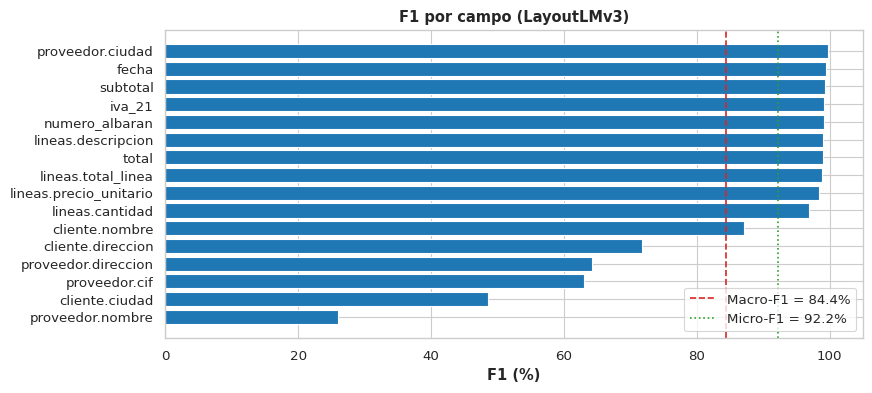

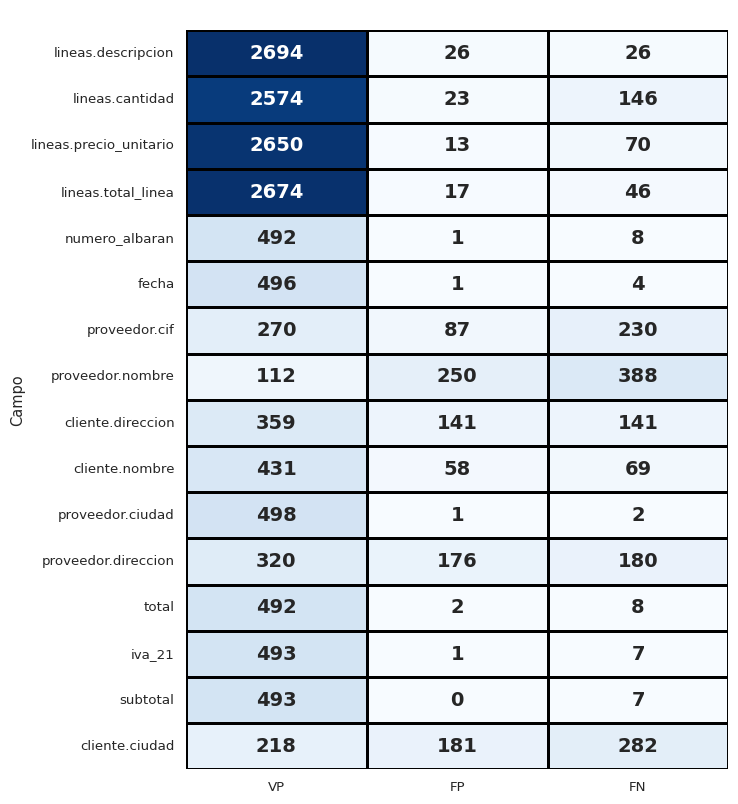

Global -> Micro-F1: 0.922 | Macro-F1: 0.844 | Weighted-F1: 0.917


,Precision,Recall,F1,CER,ANLS,Soporte
Campo,,,,,,
lineas.descripcion,99.0%,99.0%,99.0%,0.000,1.000,2720
lineas.cantidad,99.1%,94.6%,96.8%,0.051,0.946,2720
lineas.precio_unitario,99.5%,97.4%,98.5%,0.024,0.976,2720
lineas.total_linea,99.4%,98.3%,98.8%,0.014,0.986,2720
numero_albaran,99.8%,98.4%,99.1%,0.014,0.986,500
fecha,99.8%,99.2%,99.5%,0.006,0.994,500
proveedor.cif,75.6%,54.0%,63.0%,0.304,0.696,500
proveedor.nombre,30.9%,22.4%,26.0%,0.408,0.589,500
cliente.direccion,71.8%,71.8%,71.8%,0.066,0.932,500


Guardado en: /content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/03__Resultados


In [ ]:
# ==============================================================================
# 05 - F1 POR CAMPO + MATRIZ TP/FP/FN (carga metrics_layoutlmv3.json)
# ==============================================================================
import json, os
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from IPython.display import display

with open(os.path.join(CONFIG['RESULTS_DIR'], 'metrics_layoutlmv3.json'), encoding='utf-8') as f:
    M = json.load(f)
pf = M['per_field']
df = pd.DataFrame([{'Campo': k, 'Precision': v['precision'], 'Recall': v['recall'], 'F1': v['f1'],
                    'CER': v['cer'], 'ANLS': v['anls'], 'Soporte': v['support']} for k, v in pf.items()])
df = df.sort_values('Soporte', ascending=False).reset_index(drop=True)

sns.set_theme(style='whitegrid', context='paper', font_scale=1.1)
plt.figure(figsize=(9, 4))
o = df.sort_values('F1')
plt.barh(o['Campo'], o['F1']*100, color='#1f77b4')
plt.axvline(M['resumen']['macro_f1']*100, color='#d62728', linestyle='--', label=f"Macro-F1 = {M['resumen']['macro_f1']*100:.1f}%")
plt.axvline(M['resumen']['micro_f1']*100, color='#2ca02c', linestyle=':',  label=f"Micro-F1 = {M['resumen']['micro_f1']*100:.1f}%")
plt.xlabel('F1 (%)', fontweight='bold'); plt.title('F1 por campo (LayoutLMv3)', fontweight='bold')
plt.xlim(0, 105); plt.legend(loc='lower right')
plt.savefig(os.path.join(CONFIG['RESULTS_DIR'], 'tfm_f1_por_campo_layoutlmv3.pdf'), dpi=300, bbox_inches='tight', format='pdf')
plt.show()

mat = pd.DataFrame({'VP': [pf[k]['tp'] for k in df['Campo']], 'FP': [pf[k]['fp'] for k in df['Campo']],
                    'FN': [pf[k]['fn'] for k in df['Campo']]}, index=df['Campo'])
plt.figure(figsize=(7, max(3, 0.6*len(mat))))
sns.heatmap(mat, annot=True, fmt='d', cmap='Blues', cbar=False, linewidths=1, linecolor='black',
            annot_kws={'size': 14, 'weight': 'bold'})
plt.title(' ', fontweight='bold')
plt.savefig(os.path.join(CONFIG['RESULTS_DIR'], 'tfm_matriz_layoutlmv3.pdf'), dpi=300, bbox_inches='tight', format='pdf')
plt.show()

dff = df.copy()
for c in ['Precision','Recall','F1']: dff[c] = (dff[c]*100).round(1).astype(str)+'%'
dff['CER']=dff['CER'].round(3); dff['ANLS']=dff['ANLS'].round(3)
dff = dff.set_index('Campo')
print('Global -> Micro-F1: %.3f | Macro-F1: %.3f | Weighted-F1: %.3f' % (
    M['resumen']['micro_f1'], M['resumen']['macro_f1'], M['resumen']['weighted_f1']))
display(dff)
dff.to_latex(os.path.join(CONFIG['RESULTS_DIR'], 'tfm_tabla_metricas_layoutlmv3.tex'))
print('Guardado en:', CONFIG['RESULTS_DIR'])


## 06 - Curvas de aprendizaje y métricas de entrenamiento

La extracción de las curvas de convergencia se realiza mediante la lectura directa del registro histórico (`log_history`) contenido en el último archivo `trainer_state.json` almacenado en disco. Este enfoque desacopla la visualización del objeto del entrenador en memoria, permitiendo recuperar los resultados de forma autónoma.

La métrica de pasos por época (*steps/epoch*) se deriva dinámicamente del registro. El panel de visualización expone la evolución de la función de pérdida (*Cross-Entropy Loss*) tanto en entrenamiento como en validación, así como el decaimiento de la tasa de aprendizaje (*Learning Rate*).

CONVERGENCIA:


,Epoch,Step,Train Loss,Val Loss
0,0.1,50,1.7585,0.6712
1,0.2,100,0.6490,0.2407
2,0.3,150,0.3761,0.1486
3,0.4,200,0.3194,0.1208
4,0.5,250,0.2767,0.1064
5,0.6,300,0.2172,0.0918
6,0.7,350,0.1728,0.0861
7,0.8,400,0.1381,0.0799
8,0.9,450,0.1529,0.0677
9,1.0,500,0.1462,0.0611


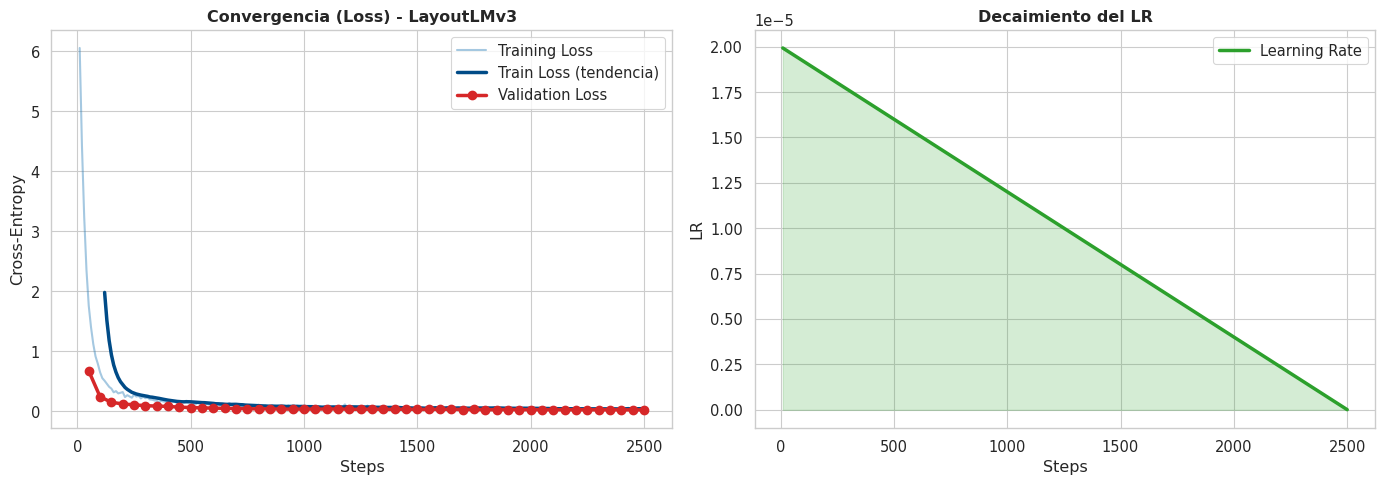

steps/epoch: 500.0


In [ ]:
# ==============================================================================
# 06 - CURVAS DE LOSS / LR (desde trainer_state.json)
# ==============================================================================
import json, glob, os
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from IPython.display import display

estados = sorted(glob.glob(os.path.join(CONFIG['CKPT_DIR'], 'checkpoint-*', 'trainer_state.json')),
                 key=lambda p: int(p.split('checkpoint-')[1].split(os.sep)[0]))
if not estados:
    raise FileNotFoundError(f"No hay trainer_state.json bajo {CONFIG['CKPT_DIR']}.")
estado = json.load(open(estados[-1], encoding='utf-8'))
log = estado['log_history']
steps_por_epoch = (estado['global_step']/estado['epoch']) if estado.get('epoch') else None

train_logs = [l for l in log if 'loss' in l and 'eval_loss' not in l]
eval_logs  = [l for l in log if 'eval_loss' in l]
tr_steps = [l['step'] for l in train_logs]; tr_loss = [l['loss'] for l in train_logs]
lr_steps = [l['step'] for l in train_logs if 'learning_rate' in l]; lrs = [l['learning_rate'] for l in train_logs if 'learning_rate' in l]
ev_steps = [l['step'] for l in eval_logs]; ev_loss = [l['eval_loss'] for l in eval_logs]

filas = []
for el in eval_logs:
    step = el['step']
    tl = next((t['loss'] for t in reversed(train_logs) if t['step'] <= step), None)
    fila = {'Step': step, 'Train Loss': round(tl,4) if tl else None, 'Val Loss': round(el['eval_loss'],4)}
    if steps_por_epoch: fila = {'Epoch': round(step/steps_por_epoch,2), **fila}
    filas.append(fila)
df_conv = pd.DataFrame(filas); print('CONVERGENCIA:'); display(df_conv)
df_conv.to_csv(os.path.join(CONFIG['RESULTS_DIR'], 'tfm_tabla_resultados_LAYOUTLMV3.csv'), index=False)
df_conv.to_latex(os.path.join(CONFIG['RESULTS_DIR'], 'tfm_tabla_resultados_LAYOUTLMV3.tex'), index=False)

sns.set_theme(style='whitegrid', context='paper', font_scale=1.2)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(tr_steps, tr_loss, color='#1f77b4', alpha=0.4, linewidth=1.5, label='Training Loss')
if len(tr_loss) > 5:
    suave = pd.Series(tr_loss).rolling(window=max(1, len(tr_loss)//20)).mean()
    ax[0].plot(tr_steps, suave, color='#004b87', linewidth=2.5, label='Train Loss (tendencia)')
ax[0].plot(ev_steps, ev_loss, marker='o', markersize=6, color='#d62728', linewidth=2.5, label='Validation Loss')
ax[0].set_title('Convergencia (Loss) - LayoutLMv3', fontweight='bold'); ax[0].set_xlabel('Steps'); ax[0].set_ylabel('Cross-Entropy'); ax[0].legend()
ax[1].plot(lr_steps, lrs, color='#2ca02c', linewidth=2.5, label='Learning Rate')
ax[1].fill_between(lr_steps, lrs, alpha=0.2, color='#2ca02c')
ax[1].set_title('Decaimiento del LR', fontweight='bold'); ax[1].set_xlabel('Steps'); ax[1].set_ylabel('LR')
ax[1].ticklabel_format(axis='y', style='sci', scilimits=(0,0)); ax[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['RESULTS_DIR'], 'tfm_curvas_entrenamiento_LAYOUTLMV3.pdf'), dpi=300, bbox_inches='tight', format='pdf')
plt.show()
print('steps/epoch:', steps_por_epoch)


## 07 - Diagnóstico cualitativo y depuración

Esta sección reúne herramientas de inspección visual para evaluar cualitativamente las predicciones de LayoutLMv3. Permite contrastar el texto transcrito por el OCR, la clasificación estructural (BIO) asignada por el modelo multimodal y el *Ground Truth* esperado, facilitando la identificación de anomalías espaciales o de segmentación.

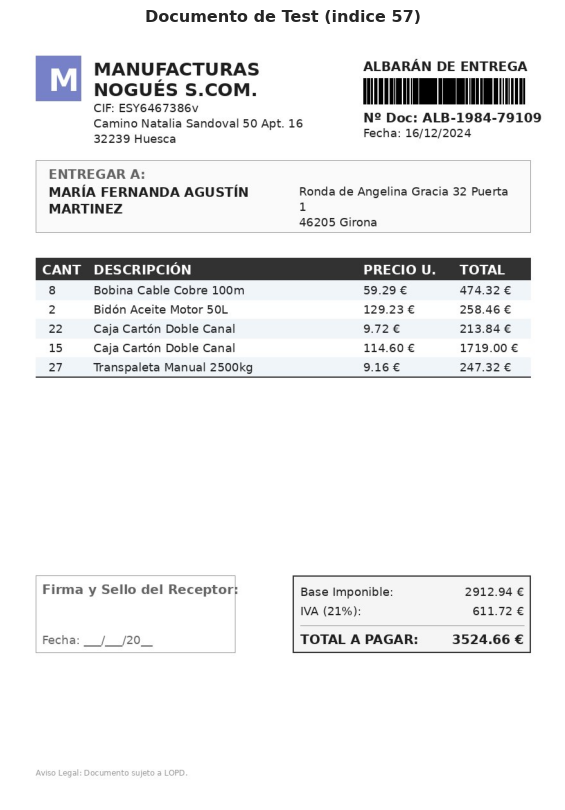

Palabras OCR detectadas: 111

  total            PRED: TOTAL A PAGAR: 3524.66         | GT: 3524.66
  numero_albaran   PRED: ALB-1984-79109                 | GT: ALB-1984-79109
  fecha            PRED: 16/12/2024                     | GT: 16/12/2024


In [ ]:
# ==============================================================================
# 07 - AUTOPSIA: imagen + OCR + prediccion vs GT
# ==============================================================================
import random, json, matplotlib.pyplot as plt

idx = random.randint(0, len(raw_dataset_test) - 1)
item = raw_dataset_test[idx]
imagen = item['image'].convert('RGB')
gt = json.loads(item['ground_truth'])['gt_parse']
pred, words = run_inference(imagen, processor, model, device, id2label,
                            key=f'test_{idx}', cache_path=CONFIG['OCR_CACHE'])

plt.figure(figsize=(8, 10)); plt.imshow(imagen); plt.axis('off')
plt.title(f'Documento de Test (indice {idx})', fontweight='bold'); plt.show()
print(f"Palabras OCR detectadas: {len(words)}\n")
for campo in ['total', 'numero_albaran', 'fecha']:
    print(f"  {campo:16s} PRED: {pred.get(campo,'') or '[vacio]':30s} | GT: {gt.get(campo,'')}")


## 08 - Análisis empírico de robustez (Test de estrés por degradación)

Esta sección implementa la evaluación del modelo frente a los cuatro conjuntos de prueba con niveles de ruido físico progresivo (severidad $\lambda \in \{0, 1, 2, 3\}$), diseñados para simular el deterioro propio del entorno industrial. El bloque opera exclusivamente en la fase de inferencia y se divide en dos rutinas[cite: 4]:

- **08a (Recuperación y carga de datos):** Extrae los laboratorios de robustez persistidos en disco y los aloja en memoria mediante una ingesta tolerante a fallos, adaptándose dinámicamente a la estructura del *split*.
- **08b (Cuantificación de degradación):** Somete la red neuronal a un test de estrés. A diferencia del escenario en dominio limpio (*caché caliente*), en esta etapa de ruido **el motor OCR externo debe reejecutarse obligatoriamente** sobre cada imagen degradada para no falsear el experimento[cite: 4]. Esto permite auditar el impacto real del estrés visual tanto en la exactitud de extracción (por la propagación de errores de segmentación espacial) como en la escalada de la latencia operativa[cite: 4]. Los resultados empíricos se persisten en `robustez_layoutlmv3.json`.

In [ ]:
# ==============================================================================
# 08a - CARGA DE LOS 4 NIVELES DE RUIDO
# ==============================================================================
import os, shutil
from datasets import load_dataset

if not os.path.exists(CONFIG['ROBUSTEZ_ZIP']):
    raise FileNotFoundError(f"No existe el ZIP de robustez: {CONFIG['ROBUSTEZ_ZIP']}")
if os.path.exists(CONFIG['LOCAL_ROBUSTEZ']):
    shutil.rmtree(CONFIG['LOCAL_ROBUSTEZ'])
shutil.unpack_archive(CONFIG['ROBUSTEZ_ZIP'], CONFIG['LOCAL_ROBUSTEZ'], 'zip')

datasets_robustez = {}
for ruido in [0, 1, 2, 3]:
    carpeta = os.path.join(CONFIG['LOCAL_ROBUSTEZ'], f'Ruido_{ruido}')
    dd = load_dataset('imagefolder', data_dir=carpeta)   # robusto: toma el split existente
    datasets_robustez[f'ruido_{ruido}'] = dd[list(dd.keys())[0]]
    print(f"  Ruido {ruido}: {len(datasets_robustez[f'ruido_{ruido}'])} docs")


KeyboardInterrupt: 

In [ ]:
# ==============================================================================
# 08b - EVALUACION DE ROBUSTEZ (12 campos, evaluador COMPARTIDO) -> robustez_layoutlmv3.json
# ==============================================================================
import json, time, os
import numpy as np
from tqdm.auto import tqdm

model.eval()
robustez = []

for ruido in [0, 1, 2, 3]:
    ds = datasets_robustez[f'ruido_{ruido}']
    nrb = len(ds)
    acc = nuevo_acc()
    errores_ocr = 0; t0 = time.time()
    _cache_estado = 'warm' if os.path.exists(CONFIG['OCR_CACHE']) else 'cold'
    with medir_recursos('eval_robustez', n_items=nrb,
                        extra={'modelo': 'LayoutLMv3', 'ruido': ruido, 'ocr_cache': _cache_estado}):
     for j in tqdm(range(nrb), desc=f'Ruido {ruido}'):
          item = ds[j]
          imagen = item['image'].convert('RGB')
          gt = json.loads(item['ground_truth'])['gt_parse']
          pred, words = run_inference(imagen, processor, model, device, id2label,
                                      key=f'rob{ruido}_{j}', cache_path=CONFIG['OCR_CACHE'])
          if not words: errores_ocr += 1
          eval_document(gt, pred, acc)          # <-- MISMO evaluador que DONUT
    _save_cache(CONFIG['OCR_CACHE'])
    dt = time.time() - t0
    per_field, resumen = agregar_metricas(acc)
    robustez.append({'ruido': ruido, 'resumen': resumen, 'per_field': per_field,
                     'ocr_vacios': errores_ocr, 'latencia_s': round(dt, 2)})
    print(f"Ruido {ruido}: Macro-F1={resumen['macro_f1']:.3f} Micro-F1={resumen['micro_f1']:.3f} | OCR vacios={errores_ocr}")

ruta = os.path.join(CONFIG['RESULTS_DIR'], 'robustez_layoutlmv3.json')
with open(ruta, 'w', encoding='utf-8') as f:
    json.dump(robustez, f, ensure_ascii=False, indent=2)
print('Guardado en:', ruta)


Ruido 0:   0%|          | 0/500 [00:00<?, ?it/s]

[BENCH] eval_robustez: 48.51s (0.097s/item) | CPU~96.8% | RAM 3135.9MB | VRAM 2531.5MB | disco R/W 0.0/0.0MB
Ruido 0: Macro-F1=0.846 Micro-F1=0.923 | OCR vacios=0


Ruido 1:   0%|          | 0/500 [00:00<?, ?it/s]

[BENCH] eval_robustez: 1715.49s (3.431s/item) | CPU~14.4% | RAM 3148.6MB | VRAM 2531.5MB | disco R/W 0.0/373.93MB
Ruido 1: Macro-F1=0.722 Micro-F1=0.678 | OCR vacios=0


Ruido 2:   0%|          | 0/500 [00:00<?, ?it/s]

[BENCH] eval_robustez: 1777.05s (3.5541s/item) | CPU~14.3% | RAM 3158.5MB | VRAM 2531.5MB | disco R/W 0.0/385.3MB
Ruido 2: Macro-F1=0.633 Micro-F1=0.608 | OCR vacios=0


Ruido 3:   0%|          | 0/500 [00:00<?, ?it/s]

[BENCH] eval_robustez: 1845.80s (3.6916s/item) | CPU~14.1% | RAM 3159.9MB | VRAM 2531.5MB | disco R/W 0.0/401.85MB
Ruido 3: Macro-F1=0.536 Micro-F1=0.529 | OCR vacios=0
Guardado en: /content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/03__Resultados/robustez_layoutlmv3.json


## 09 - Preprocesamiento Multimodal y Anotación Espacial (Fase de Entrenamiento)

Esta sección ejecuta la preparación de los datos requerida por el paradigma de clasificación de secuencias espaciales[cite: 5]. A diferencia de las arquitecturas generativas *OCR-free*, LayoutLMv3 requiere que el texto y las coordenadas espaciales (cajas delimitadoras) sean extraídos de forma anticipada como tensores de entrada[cite: 5].

Las rutinas aquí implementadas cumplen un triple objetivo metodológico:
1. Ejecutan el motor Tesseract OCR sobre las imágenes del conjunto de entrenamiento para extraer el texto estructurado[cite: 5].
2. Aplican heurísticas de saneamiento (como la normalización de separadores decimales en importes o eliminación de espacios en identificadores) para alinear las transcripciones del OCR con los valores esperados en el *Ground Truth*[cite: 2].
3. Asignan las métricas espaciales y de texto bajo el **esquema BIO** (`B-`, `I-`, `O`), garantizando que las entidades lógicas compuestas por múltiples palabras (como descripciones o direcciones) reciban sus etiquetas de continuación correctas antes del ajuste fino[cite: 2].

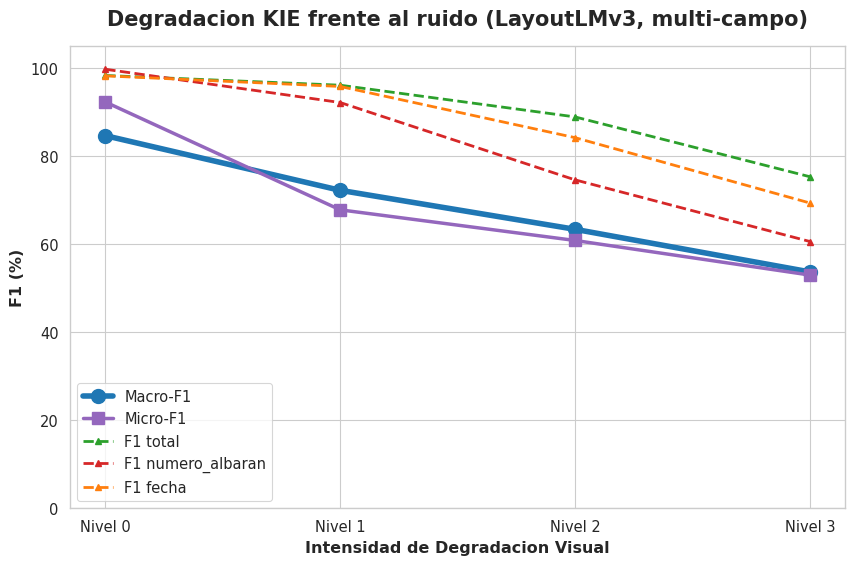

TABLA DE ROBUSTEZ:


,Macro-F1,Micro-F1,Macro-CER,Macro-ANLS,OCR vacios,Latencia (s)
Ruido,,,,,,
Nivel 0,84.6%,92.3%,0.075,0.924,0,48.98
Nivel 1,72.2%,67.8%,0.203,0.795,0,1716.07
Nivel 2,63.3%,60.8%,0.270,0.726,0,1777.91
Nivel 3,53.6%,52.9%,0.362,0.630,0,1847.52


Guardado en: /content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/03__Resultados


In [ ]:
# ==============================================================================
# 09 - DEGRADACION FRENTE AL RUIDO (carga robustez_layoutlmv3.json)
# ==============================================================================
import json, os
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from IPython.display import display

with open(os.path.join(CONFIG['RESULTS_DIR'], 'robustez_layoutlmv3.json'), encoding='utf-8') as f:
    RB = json.load(f)
x = [f"Nivel {r['ruido']}" for r in RB]
macro = [r['resumen']['macro_f1']*100 for r in RB]
micro = [r['resumen']['micro_f1']*100 for r in RB]
def f1_de(r, c): return r['per_field'].get(c, {}).get('f1', float('nan'))*100

sns.set_theme(style='whitegrid', context='paper', font_scale=1.2)
plt.figure(figsize=(10, 6))
plt.plot(x, macro, marker='o', markersize=10, linewidth=4, color='#1f77b4', label='Macro-F1')
plt.plot(x, micro, marker='s', markersize=8, linewidth=2.5, color='#9467bd', label='Micro-F1')
for campo, col in [('total','#2ca02c'), ('numero_albaran','#d62728'), ('fecha','#ff7f0e')]:
    plt.plot(x, [f1_de(r, campo) for r in RB], marker='^', linewidth=2, linestyle='--', color=col, label=f"F1 {campo}")
plt.title('Degradacion KIE frente al ruido (LayoutLMv3, multi-campo)', fontweight='bold', fontsize=15, pad=15)
plt.xlabel('Intensidad de Degradacion Visual', fontweight='bold'); plt.ylabel('F1 (%)', fontweight='bold')
plt.ylim(0, 105); plt.legend(loc='lower left')
plt.savefig(os.path.join(CONFIG['RESULTS_DIR'], 'tfm_robustez_layoutlmv3.pdf'), dpi=300, bbox_inches='tight', format='pdf')
plt.show()

filas = [{'Ruido': f"Nivel {r['ruido']}", 'Macro-F1': f"{r['resumen']['macro_f1']*100:.1f}%",
          'Micro-F1': f"{r['resumen']['micro_f1']*100:.1f}%",
          'Macro-CER': round(r['resumen']['macro_cer'],3), 'Macro-ANLS': round(r['resumen']['macro_anls'],3),
          'OCR vacios': r['ocr_vacios'], 'Latencia (s)': r['latencia_s']} for r in RB]
df_rb = pd.DataFrame(filas).set_index('Ruido')
print('TABLA DE ROBUSTEZ:'); display(df_rb)
df_rb.to_latex(os.path.join(CONFIG['RESULTS_DIR'], 'tfm_tabla_robustez_layoutlmv3.tex'))
print('Guardado en:', CONFIG['RESULTS_DIR'])


## 10 - Ajuste Fino (*Fine-Tuning*) de la Arquitectura Multimodal

Esta celda orquesta el entrenamiento de la capa de clasificación (`LayoutLMv3ForTokenClassification`) sobre el dominio logístico industrial.

Se inicializa la arquitectura preentrenada base y se despliega el optimizador empleando la API `Trainer` de Hugging Face. El entrenamiento contempla la optimización de los hiperparámetros para mitigar las limitaciones de VRAM, ajustando el tamaño del lote físico (*Batch Size*) y acumulando gradientes para garantizar la equivalencia del tamaño de lote efectivo frente a otros modelos evaluados. Asimismo, la lógica de ejecución incluye rutinas de persistencia que detectan automáticamente puntos de control (*checkpoints*) previos en Google Drive para retomar el ajuste fino en caso de interrupción del núcleo.

In [ ]:
# ==============================================================================
# 10 - TABLA COMPARATIVA: EFICIENCIA (coste por fase) + RENDIMIENTO (calidad)
# ==============================================================================
import json, os
import pandas as pd
from IPython.display import display

# ---- 1) COSTES POR FASE (de ambos modelos, persistidos por medir_recursos) ----
costes = []
if os.path.exists(CONFIG['BENCH_PATH']):
    with open(CONFIG['BENCH_PATH']) as f:
        costes = json.load(f)
if not costes:
    print('Aun no hay registros en', CONFIG['BENCH_PATH'],
          '\nEjecuta las fases (04 inferencia, 08b robustez; y 99.2/99.3 si reentrenas).')
else:
    df_cost = pd.DataFrame(costes)
    if 'dataset' in df_cost.columns:
        df_cost = df_cost[df_cost['dataset'] != 'CORD']  # excluye baseline CORD
    # Si una fase se repitio (varias corridas), nos quedamos con la ULTIMA por (modelo,fase[,ruido])
    claves = [k for k in ['modelo','fase','ruido'] if k in df_cost.columns]
    df_cost = df_cost.drop_duplicates(subset=claves, keep='last')
    cols = ['modelo','fase'] + [c for c in ['ruido','ocr_cache'] if c in df_cost.columns] + \
           [c for c in ['tiempo_s','s_por_item','cpu_pct_medio','vram_pico_mb',
                        'ram_proc_mb_fin','disk_read_mb','disk_write_mb','n_items'] if c in df_cost.columns]
    df_cost = df_cost[cols].sort_values(['modelo','fase']).reset_index(drop=True)
    print('COSTES POR FASE (eficiencia):')
    display(df_cost)
    df_cost.to_csv(os.path.join(CONFIG['RESULTS_DIR'],'benchmark_costes_tabla.csv'), index=False)

# ---- 2) METRICAS DE CALIDAD (carga los JSON de cada modelo si existen) ----
def cargar_metricas(ruta, modelo):
    if not os.path.exists(ruta):
        return None
    with open(ruta, encoding='utf-8') as f:
        M = json.load(f)
    r = M['resumen']
    fila = {'modelo': modelo, 'Macro-F1': r['macro_f1'], 'Micro-F1': r['micro_f1'],
            'Weighted-F1': r.get('weighted_f1'), 'Macro-CER': r['macro_cer'], 'Macro-ANLS': r['macro_anls']}
    return fila

filas_q = []
# LayoutLMv3 (este notebook)
f = cargar_metricas(os.path.join(CONFIG['RESULTS_DIR'],'metrics_layoutlmv3.json'), 'LayoutLMv3')
if f: filas_q.append(f)
f = cargar_metricas(os.path.join(CONFIG['RESULTS_DIR'],'metrics_paddleocr.json'), 'PaddleOCR')
if f: filas_q.append(f)
# DONUT (si ya corriste su notebook; mismo RESULTS_DIR de Drive)
f = cargar_metricas(os.path.join(CONFIG['RESULTS_DIR'],'metrics_multifield_donut.json'), 'DONUT')
if f: filas_q.append(f)

if filas_q:
    df_q = pd.DataFrame(filas_q).set_index('modelo')
    print('\nRENDIMIENTO (calidad de extraccion):')
    display(df_q.round(3))
    df_q.to_csv(os.path.join(CONFIG['RESULTS_DIR'],'benchmark_calidad_tabla.csv'))
else:
    print('\nAun no hay JSON de metricas. Ejecuta la seccion 04 (y el notebook DONUT) primero.')

# ---- 3) RESUMEN EFICIENCIA vs CALIDAD (una fila por modelo) ----
if costes and filas_q:
    dfc = pd.DataFrame(costes)
    if 'dataset' in dfc.columns:
        dfc = dfc[dfc['dataset'] != 'CORD']
    dfc = dfc.drop_duplicates(subset=[k for k in ['modelo','fase','ruido'] if k in dfc.columns], keep='last')
    def coste_inf_por_doc(modelo):
        sub = dfc[(dfc['modelo']==modelo) & (dfc['fase']=='inference_test')]
        return float(sub['s_por_item'].iloc[-1]) if len(sub) and sub['s_por_item'].notna().any() else None
    def coste_ocr_por_doc(modelo):
        sub = dfc[(dfc['modelo']==modelo) & (dfc['fase']=='preprocess_ocr')]
        return float(sub['s_por_item'].iloc[-1]) if len(sub) and sub['s_por_item'].notna().any() else 0.0
    res = []
    for fila in filas_q:
        m = fila['modelo']
        inf = coste_inf_por_doc(m); ocr = coste_ocr_por_doc(m)
        res.append({'modelo': m, 'Macro-F1': round(fila['Macro-F1'],3),
                    'OCR s/doc': round(ocr,3) if ocr is not None else None,
                    'Inferencia s/doc': round(inf,3) if inf is not None else None,
                    'Coste total s/doc': round((ocr or 0)+(inf or 0),3) if inf is not None else None})
    df_res = pd.DataFrame(res).set_index('modelo')
    print('\nEFICIENCIA vs CALIDAD (resumen por documento):')
    display(df_res)
    df_res.to_latex(os.path.join(CONFIG['RESULTS_DIR'],'benchmark_resumen.tex'))
    print('Tablas guardadas en:', CONFIG['RESULTS_DIR'])


## 10b - Benchmarking comparativo: Eficiencia computacional vs. Calidad de extracción

Esta sección procesa y unifica los registros de consumo de recursos computacionales, uso de memoria RAM/VRAM y latencia (`benchmark_costes.json`), cruzándolos con la métrica cualitativa de extracción (Macro-F1).

El análisis consolida una de las principales vulnerabilidades de operabilidad de LayoutLMv3: la fuerte dependencia de la etapa de preprocesamiento de texto (`preprocess_ocr`). Al ejecutarse en un entorno logístico dinámico sin posibilidad de almacenar transcripciones en caché, el tiempo de ejecución del OCR en la CPU se convierte en un cuello de botella, limitando la latencia global del proceso por documento frente a modelos *End-to-End*. Los datos extraídos en este bloque estructuran las tablas analíticas y de eficiencia incluidas en la memoria del proyecto.

In [ ]:
# ==============================================================================
# 10b - TABLA COMPARATIVA POR CAMPO  (DONUT vs LayoutLMv3, esquema SCORABLE comun)
#       Lee metrics_multifield_donut.json y metrics_layoutlmv3.json de RESULTS_DIR.
# ==============================================================================
import json, os
import numpy as np, pandas as pd
import seaborn as sns, matplotlib.pyplot as plt
from IPython.display import display

RES = CONFIG['RESULTS_DIR']
RUTAS = {'DONUT': os.path.join(RES, 'metrics_multifield_donut.json'),
         'LayoutLMv3': os.path.join(RES, 'metrics_layoutlmv3.json')}

M = {}
for modelo, ruta in RUTAS.items():
    if not os.path.exists(ruta):
        raise FileNotFoundError(f"Falta {ruta}. Ejecuta la evaluacion de {modelo} (seccion 04) primero.")
    with open(ruta, encoding='utf-8') as f:
        M[modelo] = json.load(f)

# Orden y etiquetas legibles (planos -> lineas). Debe cubrir el evaluador comun.
ORDEN = [
    ('numero_albaran',        'Numero albaran'),
    ('fecha',                 'Fecha'),
    ('proveedor.cif',         'CIF proveedor'),
    ('subtotal',              'Subtotal'),
    ('iva_21',                'IVA (21%)'),
    ('total',                 'Total'),
    ('lineas.descripcion',    'Linea - descripcion'),
    ('lineas.cantidad',       'Linea - cantidad'),
    ('lineas.precio_unitario','Linea - precio unit.'),
    ('lineas.total_linea',    'Linea - total linea'),
]

# ---- CHEQUEO DE COMPARABILIDAD -------------------------------------------
# Mismo test set + mismo GT => el soporte (tp+fn) de cada campo DEBE coincidir
# entre modelos. Si no, las particiones divergieron y la comparativa NO es valida.
avisos = []
nd = {m: M[m].get('n_docs') for m in M}
if len(set(nd.values())) > 1:
    avisos.append(f"n_docs distinto entre modelos: {nd} -> particiones NO alineadas.")
for key, _ in ORDEN:
    sup = {m: M[m]['per_field'].get(key, {}).get('support') for m in M}
    vals = [s for s in sup.values() if s is not None]
    if len(vals) == len(M) and len(set(vals)) > 1:
        avisos.append(f"Soporte distinto en '{key}': {sup} -> revisar particion/GT.")

# ---- TABLA POR CAMPO ------------------------------------------------------
filas = []
for key, etiqueta in ORDEN:
    d = M['DONUT']['per_field'].get(key)
    l = M['LayoutLMv3']['per_field'].get(key)
    f1_d = d['f1'] if d else float('nan')
    f1_l = l['f1'] if l else float('nan')
    sup  = (d or l or {}).get('support', 0)
    filas.append({
        'Campo': etiqueta,
        'F1 DONUT':  round(f1_d, 3),
        'F1 LayoutLMv3': round(f1_l, 3),
        'delta (D-L)': round(f1_d - f1_l, 3) if not (np.isnan(f1_d) or np.isnan(f1_l)) else float('nan'),
        'ANLS DONUT': round(d['anls'], 3) if d else float('nan'),
        'ANLS LayoutLMv3': round(l['anls'], 3) if l else float('nan'),
        'Soporte': sup,
    })
df = pd.DataFrame(filas).set_index('Campo')

# ---- RESUMEN AGREGADO -----------------------------------------------------
resumen = pd.DataFrame({
    m: {'Micro-F1': M[m]['resumen']['micro_f1'],
        'Macro-F1': M[m]['resumen']['macro_f1'],
        'Weighted-F1': M[m]['resumen']['weighted_f1'],
        'Macro-ANLS': M[m]['resumen']['macro_anls'],
        's/doc': M[m].get('tiempo_por_doc_s', float('nan'))}
    for m in ['DONUT', 'LayoutLMv3']
}).T.round(3)

print('='*84)
print('COMPARATIVA POR CAMPO  (10 campos, esquema SCORABLE identico en ambos modelos)')
print('='*84)
display(df)
print('\nAGREGADOS (sobre el MISMO conjunto de 10 campos -> comparables):')
display(resumen)
if avisos:
    print('\n[AVISO DE COMPARABILIDAD]')
    for a in avisos: print('  -', a)
else:
    print('\n[OK] Soporte por campo y n_docs coinciden: la comparativa es valida.')

# ---- EXPORTES (LaTeX + grafico) ------------------------------------------
df.to_latex(os.path.join(RES, 'tfm_comparativa_por_campo.tex'), na_rep='--',
            caption='Comparativa por campo (F1) entre DONUT y LayoutLMv3 sobre el esquema SCORABLE comun.',
            label='tab:comp_campos')
resumen.to_latex(os.path.join(RES, 'tfm_comparativa_agregada.tex'),
                 caption='Metricas agregadas sobre los 10 campos comunes.', label='tab:comp_agregada')

sns.set_theme(style='whitegrid', context='paper', font_scale=1.1)
etiquetas = [e for _, e in ORDEN]
y = np.arange(len(etiquetas)); h = 0.4
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(y + h/2, df['F1 DONUT'].values,      height=h, label='DONUT',      color='#1f77b4')
ax.barh(y - h/2, df['F1 LayoutLMv3'].values, height=h, label='LayoutLMv3', color='#ff7f0e')
ax.set_yticks(y); ax.set_yticklabels(etiquetas); ax.invert_yaxis()
ax.set_xlabel('F1 (coincidencia exacta)'); ax.set_xlim(0, 1.02)
ax.axhline(5.5, color='0.6', lw=1, ls='--')   # separa planos (arriba) de lineas (abajo)
ax.text(0.01, 5.55, 'lineas ->', fontsize=8, color='0.4', va='top')
ax.set_title('F1 por campo: DONUT vs LayoutLMv3', fontweight='bold', pad=12)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(RES, 'tfm_comparativa_por_campo.pdf'), dpi=300, bbox_inches='tight', format='pdf')
plt.show()
print('Guardado: tfm_comparativa_por_campo.{tex,pdf} y tfm_comparativa_agregada.tex en', RES)


## 99 - Anexo Técnico: Generación de Datos, Preprocesamiento y Ajuste Fino

Este bloque agrupa las rutinas fundacionales del experimento. Su ejecución está reservada exclusivamente para la construcción inicial del entorno logístico y el entrenamiento del modelo desde cero. **No debe ejecutarse durante el flujo estándar de evaluación.**

Las subsecciones documentan de forma reproducible la creación del corpus sintético, la inyección de estrés visual, la canalización del motor OCR y la optimización de los pesos de la red neuronal.

### 99.1 - Generación masiva del conjunto de datos sintético (Dominio Logístico)

Esta celda implementa el motor de renderizado estructurado para construir el *dataset* base de la investigación. Mediante las librerías `Faker` y `Pillow`, se generan 5.000 albaranes de entrega representativos de la industria logística española, asegurando la heterogeneidad espacial y la presencia de caracteres acentuados (tipografía *DejaVu Sans*).

Para garantizar el aislamiento de los datos y evitar la memorización o el sobreajuste (*data leakage*), el corpus se divide mediante una partición estratificada estática (80% entrenamiento, 10% validación, 10% prueba) controlada estrictamente por la semilla determinista `seed=42`.

In [ ]:
# ==============================================================================
# 99.1 - MOTOR DE RENDERIZADO "CORPORATE" (ALTA FIDELIDAD)
# ==============================================================================
import os
import json
import random
import numpy as np
import matplotlib.pyplot as plt
from faker import Faker
from PIL import Image, ImageDraw, ImageFont

fake = Faker('es_ES')

ARTICULOS_LOGISTICOS = [
    "Palet Europeo 1200x800", "Caja Tornillos Hexagonales M8",
    "Bobina Cable Cobre 100m", "Bidón Aceite Motor 50L",
    "Film Estirable Transparente", "Cinta Adhesiva Embalaje",
    "Estantería Metálica Carga", "Transpaleta Manual 2500kg",
    "Caja Cartón Doble Canal", "Kit Herramientas Básicas"
]

class GeneradorAlbaranesPro:
    def __init__(self):
        try:
            self.f_tiny = ImageFont.truetype("Roboto-Regular.ttf", 12)
            self.f_normal = ImageFont.truetype("Roboto-Regular.ttf", 18)
            self.f_bold = ImageFont.truetype("Roboto-Bold.ttf", 20)
            self.f_title = ImageFont.truetype("Roboto-Bold.ttf", 32)
            self.f_logo = ImageFont.truetype("Roboto-Bold.ttf", 48)
        except IOError:
            print("Usando fuentes por defecto (No recomendado para alta fidelidad)")
            self.f_tiny = self.f_normal = self.f_bold = self.f_title = self.f_logo = ImageFont.load_default()

    def generar_datos_json(self):
        num_lineas = random.randint(3, 8)
        lineas = []
        subtotal = 0.0

        for _ in range(num_lineas):
            cant = random.randint(1, 50)
            precio_uni = round(random.uniform(5.0, 150.0), 2)
            total_linea = round(cant * precio_uni, 2)
            subtotal += total_linea
            lineas.append({"descripcion": random.choice(ARTICULOS_LOGISTICOS), "cantidad": cant, "precio_unitario": precio_uni, "total_linea": total_linea})

        iva = round(subtotal * 0.21, 2)
        total_pagar = round(subtotal + iva, 2)

        return {
            "tipo_documento": "ALBARÁN DE ENTREGA",
            "numero_albaran": f"ALB-{fake.year()}-{random.randint(10000, 99999)}",
            "fecha": fake.date_this_decade().strftime("%d/%m/%Y"),
            "proveedor": {"nombre": fake.company(), "direccion": fake.street_address(), "ciudad": f"{fake.postcode()} {fake.city()}", "cif": fake.vat_id()},
            "cliente": {"nombre": fake.name(), "direccion": fake.street_address(), "ciudad": f"{fake.postcode()} {fake.city()}"},
            "lineas": lineas, "subtotal": subtotal, "iva_21": iva, "total": total_pagar
        }

    def _dibujar_codigo_barras(self, draw, x_start, y_start, width, height):
        x = x_start
        while x < x_start + width:
            w = random.randint(1, 4)
            draw.rectangle([x, y_start, x+w, y_start+height], fill=(0,0,0))
            x += w + random.randint(1, 3)

    def dibujar_albaran(self, datos):
        img = Image.new('RGB', (850, 1200), color=(255, 255, 255))
        draw = ImageDraw.Draw(img)
        text_color = (30, 30, 30)

        # --- CABECERA SUPERIOR ---
        color_logo = (random.randint(50, 200), random.randint(50, 200), random.randint(50, 200))
        draw.rectangle([40, 40, 110, 110], fill=color_logo)
        draw.text((60, 50), datos['proveedor']['nombre'][0], font=self.f_logo, fill=(255, 255, 255))

        # 2. Datos Proveedor (Límites más estrictos)
        nombre_prov = datos['proveedor']['nombre'].upper()
        if len(nombre_prov) > 18:
            nombre_prov = nombre_prov[:18].strip() + "."

        draw.text((130, 45), nombre_prov, font=self.f_title, fill=text_color)
        draw.text((130, 85), f"CIF: {datos['proveedor']['cif']}", font=self.f_normal, fill=text_color)
        draw.text((130, 110), datos['proveedor']['direccion'][:28], font=self.f_normal, fill=text_color)
        draw.text((130, 135), datos['proveedor']['ciudad'][:28], font=self.f_normal, fill=text_color)

        # 3. Metadatos Documento
        draw.text((550, 45), datos['tipo_documento'], font=self.f_bold, fill=text_color)
        self._dibujar_codigo_barras(draw, 550, 75, 250, 40)
        draw.text((550, 125), f"Nº Doc: {datos['numero_albaran']}", font=self.f_bold, fill=text_color)
        draw.text((550, 150), f"Fecha: {datos['fecha']}", font=self.f_normal, fill=text_color)

        # --- SECCIÓN CLIENTE ---
        draw.rectangle([40, 190, 810, 290], outline=(150, 150, 150), width=1, fill=(250, 250, 250))
        draw.text((60, 200), "ENTREGAR A:", font=self.f_bold, fill=(100, 100, 100))

        nombre_cli = datos['cliente']['nombre'].upper()
        if len(nombre_cli) > 25: nombre_cli = nombre_cli[:25].strip() + "."
        draw.text((60, 230), nombre_cli, font=self.f_bold, fill=text_color)

        draw.text((450, 230), datos['cliente']['direccion'][:30], font=self.f_normal, fill=text_color)
        draw.text((450, 255), datos['cliente']['ciudad'][:30], font=self.f_normal, fill=text_color)

        # --- TABLA DE LÍNEAS ---
        y_actual = 330
        draw.rectangle([40, y_actual, 810, y_actual+35], fill=(50, 50, 50))
        draw.text((50, y_actual+7), "CANT", font=self.f_bold, fill=(255, 255, 255))
        draw.text((130, y_actual+7), "DESCRIPCIÓN", font=self.f_bold, fill=(255, 255, 255))
        draw.text((550, y_actual+7), "PRECIO U.", font=self.f_bold, fill=(255, 255, 255))
        draw.text((700, y_actual+7), "TOTAL", font=self.f_bold, fill=(255, 255, 255))

        y_actual += 35
        for idx, linea in enumerate(datos['lineas']):
            if idx % 2 == 0:
                draw.rectangle([40, y_actual, 810, y_actual+30], fill=(240, 245, 250))

            draw.text((60, y_actual+5), str(linea['cantidad']), font=self.f_normal, fill=text_color)
            draw.text((130, y_actual+5), linea['descripcion'][:30], font=self.f_normal, fill=text_color)
            draw.text((550, y_actual+5), f"{linea['precio_unitario']:.2f} €", font=self.f_normal, fill=text_color)
            draw.text((700, y_actual+5), f"{linea['total_linea']:.2f} €", font=self.f_normal, fill=text_color)
            y_actual += 30

        draw.line([(40, y_actual), (810, y_actual)], fill=(50,50,50), width=2)

        # --- SECCIÓN INFERIOR ---
        y_totales = max(y_actual + 40, 850)
        draw.rectangle([40, y_totales, 350, y_totales+120], outline=(150,150,150), width=1)
        draw.text((50, y_totales+10), "Firma y Sello del Receptor:", font=self.f_bold, fill=(100,100,100))
        draw.text((50, y_totales+90), f"Fecha: ___/___/20__", font=self.f_normal, fill=(100,100,100))

        draw.rectangle([500, y_totales, 810, y_totales+120], fill=(245,245,245), outline=(50,50,50), width=2)
        draw.text((520, y_totales+15), "Base Imponible:", font=self.f_normal, fill=text_color)
        draw.text((700, y_totales+15), f"{datos['subtotal']:.2f} €", font=self.f_normal, fill=text_color)
        draw.text((520, y_totales+45), "IVA (21%):", font=self.f_normal, fill=text_color)
        draw.text((700, y_totales+45), f"{datos['iva_21']:.2f} €", font=self.f_normal, fill=text_color)
        draw.line([(520, y_totales+75), (790, y_totales+75)], fill=(150,150,150), width=1)
        draw.text((520, y_totales+85), "TOTAL A PAGAR:", font=self.f_bold, fill=text_color)
        draw.text((700, y_totales+85), f"{datos['total']:.2f} €", font=self.f_bold, fill=text_color)

        texto_legal = "Aviso Legal: Documento mercantil sujeto a la Ley 15/1999 de Protección de Datos de Carácter Personal (LOPD). La mercancía viaja por cuenta y riesgo del comprador."
        draw.text((40, 1150), texto_legal, font=self.f_tiny, fill=(150,150,150))

        return img

# ==============================================================================
# DEMOSTRACIÓN VISUAL (COMPARA EL ANTES Y EL DESPUÉS)
# ==============================================================================
generador_pro = GeneradorAlbaranesPro()
datos_pro = generador_pro.generar_datos_json()
img_pro = generador_pro.dibujar_albaran(datos_pro)

plt.figure(figsize=(10, 14))
plt.imshow(img_pro)
plt.title("Albarán Generado (Logística Industrial)", fontsize=16, fontweight='bold')
plt.axis('off')
plt.show()

In [ ]:
# ==============================================================================
# CELDA 7: GENERACIÓN MASIVA DEL DATASET SINTÉTICO Y GUARDADO EN DRIVE
# ==============================================================================
import os
import json
import shutil
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import albumentations as A
from google.colab import drive

# ------------------------------------------------------------------------------
# 1. CONEXIÓN A GOOGLE DRIVE (Blindaje inicial)
# ------------------------------------------------------------------------------
print("🔌 Conectando a Google Drive...")
drive.mount('/content/drive')

# ------------------------------------------------------------------------------
# 2. CONFIGURACIÓN Y PIPELINES
# ------------------------------------------------------------------------------
# Pipeline de degradación progresiva para simular el almacén
def get_noise_pipeline(severity=1):
    return A.Compose([
        A.MotionBlur(p=min(1.0, 0.3 * severity)),
        A.RandomBrightnessContrast(p=min(1.0, 0.4 * severity)),
        A.CoarseDropout(max_holes=5*severity, max_height=20, max_width=20, p=min(1.0, 0.2 * severity)),
        A.SafeRotate(limit=5 * severity, p=0.5)
    ])

NUM_IMAGENES = 5000
NIVEL_RUIDO = 3
LOCAL_DIR = "/content/TFM_Dataset_Logistica"
IMG_DIR = os.path.join(LOCAL_DIR, "images")
METADATA_FILE = os.path.join(LOCAL_DIR, "metadata.jsonl")
DRIVE_DESTINATION = "/content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/01__Dataset/TFM_Dataset_Logistica.zip"

# Limpieza previa en la RAM de Colab
if os.path.exists(LOCAL_DIR): shutil.rmtree(LOCAL_DIR)
os.makedirs(IMG_DIR, exist_ok=True)

print(f"\n Iniciando generación de {NUM_IMAGENES} albaranes CORPORATIVOS...")
print("Aplicando degradación física severa (Ruido Nivel 3)...")

# ------------------------------------------------------------------------------
# 3. GENERACIÓN DEL DATASET
# ------------------------------------------------------------------------------
# Instancias
generador_pro = GeneradorAlbaranesPro() # Se asume que está en memoria de una celda anterior
pipeline_ruido = get_noise_pipeline(severity=NIVEL_RUIDO)
ejemplos_visuales = []

with open(METADATA_FILE, 'w', encoding='utf-8') as f_meta:
    for i in tqdm(range(NUM_IMAGENES), desc="Generando Dataset Sintético"):
        # 1. Generar Datos e Imagen Pro
        datos_json = generador_pro.generar_datos_json()
        img_limpia_pil = generador_pro.dibujar_albaran(datos_json)

        # 2. Aplicar degradación física (Albumentations)
        img_np = np.array(img_limpia_pil)
        img_degradada_np = pipeline_ruido(image=img_np)['image']
        img_final_pil = Image.fromarray(img_degradada_np)

        # 3. Guardar imagen
        nombre_archivo = f"albaran_pro_{i:05d}.jpg"
        ruta_img = os.path.join(IMG_DIR, nombre_archivo)
        img_final_pil.save(ruta_img, format="JPEG", quality=85)

        # 4. Guardar Ground Truth (¡INCLUYE EL PARCHE DE 'images/' NATIVAMENTE!)
        estructura_hf = {
            "file_name": f"images/{nombre_archivo}",
            "ground_truth": json.dumps({"gt_parse": datos_json}, ensure_ascii=False)
        }
        f_meta.write(json.dumps(estructura_hf, ensure_ascii=False) + "\n")

        if i < 10: ejemplos_visuales.append(img_final_pil)

# ------------------------------------------------------------------------------
# 4. EMPAQUETADO Y TRANSFERENCIA
# ------------------------------------------------------------------------------
print("\n Comprimiendo el dataset a un archivo ZIP...")
shutil.make_archive(LOCAL_DIR, 'zip', LOCAL_DIR)

print(f"Transfiriendo ZIP a Google Drive -> {DRIVE_DESTINATION}...")
shutil.copy(LOCAL_DIR + ".zip", DRIVE_DESTINATION)
print("¡Dataset generado y guardado permanentemente con éxito en tu Drive!")

# Visualización rápida
fig, axes = plt.subplots(2, 5, figsize=(20, 10))
for idx, img in enumerate(ejemplos_visuales):
    axes.flatten()[idx].imshow(img)
    axes.flatten()[idx].axis('off')
plt.tight_layout()
plt.show()

### 99.2 - Instanciación del laboratorio de robustez (Test de estrés visual)

Construcción de los escenarios de evaluación *Out-of-Distribution* (OOD). Se generan cuatro conjuntos de prueba independientes compuestos por 500 documentos cada uno, aplicando niveles progresivos de degradación física (manchas, ruido, desenfoque y rotaciones) mediante la librería `Albumentations`.

Para asegurar la validez empírica del estudio y evitar cualquier sesgo en el modelo, estos conjuntos alterados se generan empleando una semilla algorítmica independiente (`seed=2025`) y se reservan **exclusivamente para la fase de inferencia**.


In [ ]:
# ==============================================================================
# 99.2 - RE-PROCESADO CON ETIQUETADO BIO CORREGIDO  (one-time)
# ==============================================================================
# Requiere SOLO el ZIP del dataset en Drive (CONFIG['DATASET_ZIP']); NO requiere
# haber ejecutado 99.1 (gen). Se apoya en la extraccion que hace la seccion 02.
# >>> Es el MISMO dataset que usa el notebook de DONUT: asi la comparacion
#     DONUT vs LayoutLMv3 es valida (mismas imagenes, mismo GT, misma particion).
import json, os, shutil
from datasets import load_dataset
from transformers import AutoProcessor

# 1. Asegura el dataset crudo en local (idempotente). Si la seccion 02 ya lo
#    extrajo, reutiliza 'raw_dataset'; si no, lo extrae del ZIP de Drive.
if 'raw_dataset' in globals():
    raw = raw_dataset
    print('Reutilizando raw_dataset de la seccion 02.')
else:
    if not os.path.exists(CONFIG['DATASET_ZIP']):
        raise FileNotFoundError(f"Falta el ZIP del dataset en Drive: {CONFIG['DATASET_ZIP']}")
    if not os.path.exists(CONFIG['LOCAL_DATASET']):
        shutil.unpack_archive(CONFIG['DATASET_ZIP'], CONFIG['LOCAL_DATASET'], 'zip')
    raw = load_dataset('imagefolder', data_dir=CONFIG['LOCAL_DATASET'], split='train')
    print('Dataset crudo cargado desde Drive (sin ejecutar 99.1).')

# 2. Processor SIN apply_ocr (el OCR lo hacemos nosotros, mismo que en evaluacion)
processor = AutoProcessor.from_pretrained('microsoft/layoutlmv3-base', apply_ocr=False)

def preparar_ejemplo(ejemplo):
    imagen = ejemplo['image'].convert('RGB')
    gt = json.loads(ejemplo['ground_truth'])['gt_parse']
    words, boxes = ocr_words_boxes(imagen)              # mismo OCR que en evaluacion
    ner_tags = asignar_bio(words, boxes, gt)                   # etiquetado corregido (B-/I-, normalizado)
    enc = processor(imagen, words, boxes=boxes, word_labels=ner_tags,
                    truncation=True, padding='max_length', max_length=CONFIG['MAX_LEN'], return_tensors='pt')
    return {k: v.squeeze(0) for k, v in enc.items()}

_n = len(raw)
with medir_recursos('preprocess_ocr', n_items=_n, extra={'modelo': 'LayoutLMv3', 'ocr_cache': 'cold'}):
    processed = raw.map(preparar_ejemplo, remove_columns=raw.column_names, desc='OCR + BIO corregido')
    processed.save_to_disk(CONFIG['PROCESSED_DS'])

# 3. MISMA particion que el notebook DONUT y que la seccion 02 (semilla 42)
s1 = processed.train_test_split(test_size=0.2, seed=CONFIG['SEED'])
s2 = s1['test'].train_test_split(test_size=0.5, seed=CONFIG['SEED'])
dataset_train, dataset_val, dataset_test = s1['train'], s2['train'], s2['test']
print('Dataset re-etiquetado guardado en', CONFIG['PROCESSED_DS'])
print(f'Train {len(dataset_train)} | Val {len(dataset_val)} | Test {len(dataset_test)}')


Resolving data files:   0%|          | 0/5001 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Dataset crudo cargado desde Drive (sin ejecutar 99.1).


preprocessor_config.json:   0%|          | 0.00/275 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.14k [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

OCR + BIO corregido:   0%|          | 0/5000 [00:00<?, ? examples/s]

Saving the dataset (0/7 shards):   0%|          | 0/5000 [00:00<?, ? examples/s]

[BENCH] preprocess_ocr: 16068.97s (3.2138s/item) | CPU~11.1% | RAM 2734.0MB | VRAM 0.0MB | disco R/W 3309.42/6328.38MB
Dataset re-etiquetado guardado en /content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/01__Dataset/TFM_Dataset_LayoutLMv3_Procesado
Train 4000 | Val 500 | Test 500


Tiempo Total de etiquetado BIO -> 4h 25min para 5.000 imágenes

### 99.3 - Preprocesamiento OCR, saneamiento y anotación espacial (Esquema BIO)

A diferencia de los paradigmas generativos *OCR-Free* (como DONUT), la arquitectura LayoutLMv3 exige que el texto y las coordenadas espaciales (*bounding boxes*) se extraigan anticipadamente. Esta celda orquesta la canalización de datos (*pipeline*) previa al entrenamiento:

1. **Reconocimiento Óptico:** Ejecución del motor externo Tesseract OCR sobre las imágenes limpias del corpus.
2. **Saneamiento y Normalización:** Aplicación de heurísticas de limpieza para unificar formatos numéricos (separadores decimales) y alinear la transcripción óptica con el *Ground Truth* esperado.
3. **Mapeo Espacial:** Asignación de etiquetas bajo el esquema de clasificación **BIO** (`B-`, `I-`, `O`). Se implementan anclajes espaciales guiados por el eje Y para garantizar que las entidades compuestas por múltiples *tokens* (como direcciones o descripciones de artículos en tablas) conserven su integridad estructural.

### 99.3b - Mitigación heurística de errores de segmentación OCR (*Data Imputation*)

Durante el preprocesamiento de la línea base, se detectaron errores sistemáticos en la canalización óptica asociados a la tipografía corporativa de los albaranes. El motor externo (Tesseract) exhibía dificultades para segmentar correctamente caracteres críticos en la logística europea, como guiones en identificadores (`ALB-2012` leído como `ALB2012`) o separadores decimales en importes (`29799.53` leído como `2979953`)[cite: 8].

Para evitar la contaminación del *Ground Truth* y garantizar la validez del entrenamiento, se implementaron rutinas de saneamiento activo (*Data Imputation*). Las funciones `sanear_total` y `sanear_albaran` validan las expresiones regulares y reconstruyen físicamente la puntuación omitida por el OCR[cite: 8], garantizando que el modelo reciba secuencias de texto inmaculadas previas a la anotación de coordenadas 2D.

In [ ]:
# ==============================================================================
# 99.3b - COBERTURA BIO DE CAMPOS CORTOS sobre el DATASET LIMPIO (re-medicion)
# ==============================================================================
# Decide si el "techo de OCR" era real o un artefacto del dataset viejo
# (fuente load_default sin acentos + ruido-3). Mide numero/fecha/cif/subtotal/
# iva/total + lineas con el asignar_bio actual (match exacto).
import json, collections, os

# --- Resolucion robusta del TEST SPLIT (corras lo que corras antes) ---
if 'raw_dataset_test' in globals():
    _ds = raw_dataset_test
elif 'raw_dataset' in globals():
    _s1 = raw_dataset.train_test_split(test_size=0.2, seed=CONFIG['SEED'])
    _ds = _s1['test'].train_test_split(test_size=0.5, seed=CONFIG['SEED'])['test']
    print("Derivado el test split desde raw_dataset.")
else:
    import shutil as _sh
    from datasets import load_dataset as _ld
    if not os.path.exists(CONFIG['LOCAL_DATASET']):
        _sh.unpack_archive(CONFIG['DATASET_ZIP'], CONFIG['LOCAL_DATASET'], 'zip')
    _raw = _ld('imagefolder', data_dir=CONFIG['LOCAL_DATASET'], split='train')
    _s1 = _raw.train_test_split(test_size=0.2, seed=CONFIG['SEED'])
    _ds = _s1['test'].train_test_split(test_size=0.5, seed=CONFIG['SEED'])['test']
    print("Cargado dataset desde ZIP y derivado el test split.")

# --- CRITICO: borrar cache OCR viejo (claves test_{idx} apuntan a imagenes nuevas) ---
globals()['_OCR_CACHE'] = None
if os.path.exists(CONFIG['OCR_CACHE']):
    os.remove(CONFIG['OCR_CACHE']); print("Cache OCR borrada (se repuebla con el dataset limpio).")

N_DIAG = min(60, len(_ds))
cov = collections.Counter(); gt_present = collections.Counter()
lineas_gt = lineas_lbl = 0

for idx in range(N_DIAG):
    item = _ds[idx]
    gt = json.loads(item['ground_truth'])['gt_parse']
    words, boxes = ocr_words_boxes(item['image'].convert('RGB'), key=f'test_{idx}', cache_path=CONFIG['OCR_CACHE'])
    if not words:
        continue
    tags = asignar_bio(words, boxes, gt)
    presentes = {id2label[t].split('-', 1)[1] for t in tags if t != label2id['O']}
    for path, tag, _ in FLAT_FIELDS:
        if _gt_get(gt, path):
            gt_present[tag] += 1
            if tag in presentes: cov[tag] += 1
    filas_gt = [l for l in (gt.get('lineas') or []) if isinstance(l, dict) and str(l.get('descripcion','')).strip()]
    lineas_gt += len(filas_gt)
    lineas_lbl += sum(1 for t in tags if t == label2id['B-LDESC'])
    for col_key, tag, _ in LINE_COLS:
        n_gt = sum(1 for l in filas_gt if str(l.get(col_key, '')).strip())
        gt_present[tag] += n_gt
        cov[tag] += sum(1 for t in tags if t == label2id['B-' + tag])

print('='*72)
print(f'COBERTURA BIO sobre {N_DIAG} docs LIMPIOS (etiquetados / presentes en GT)')
print('='*72)
for _, tag, _ in FLAT_FIELDS:
    g = gt_present[tag]; print(f'  {tag:9s} {cov[tag]:4d}/{g:<4d}  ({100*cov[tag]/g if g else 0:5.1f}%)')
print('  --- lineas ---')
for _, tag, _ in LINE_COLS:
    g = gt_present[tag]; print(f'  {tag:9s} {cov[tag]:4d}/{g:<4d}  ({100*cov[tag]/g if g else 0:5.1f}%)')
print(f'  filas: {lineas_lbl}/{lineas_gt} descripciones ancladas ({100*lineas_lbl/lineas_gt if lineas_gt else 0:.1f}%)')
print('='*72)
print('COMPARA con la corrida vieja (~15%): si sube mucho, el techo era el dataset, no Tesseract.')

COBERTURA BIO sobre 60 docs LIMPIOS (etiquetados / presentes en GT)
  NUMERO      59/60    ( 98.3%)
  FECHA       59/60    ( 98.3%)
  CIF         28/60    ( 46.7%)
  SUBTOTAL    57/60    ( 95.0%)
  IVA         60/60    (100.0%)
  TOTAL       60/60    (100.0%)
  --- lineas ---
  LDESC      296/296   (100.0%)
  LCANT      276/296   ( 93.2%)
  LPU        291/296   ( 98.3%)
  LTL        293/296   ( 99.0%)
  filas: 296/296 descripciones ancladas (100.0%)
COMPARA con la corrida vieja (~15%): si sube mucho, el techo era el dataset, no Tesseract.


In [ ]:
# ==============================================================================
# 99.3c - POR QUE FALLAN CIF Y SUBTOTAL (ausente / presente-O / robado)
# ==============================================================================
import json, collections, os

# --- resolucion robusta del test split ---
if 'raw_dataset_test' in globals():
    _ds = raw_dataset_test
elif 'raw_dataset' in globals():
    _s1 = raw_dataset.train_test_split(test_size=0.2, seed=CONFIG['SEED'])
    _ds = _s1['test'].train_test_split(test_size=0.5, seed=CONFIG['SEED'])['test']
else:
    import shutil as _sh
    from datasets import load_dataset as _ld
    if not os.path.exists(CONFIG['LOCAL_DATASET']):
        _sh.unpack_archive(CONFIG['DATASET_ZIP'], CONFIG['LOCAL_DATASET'], 'zip')
    _raw = _ld('imagefolder', data_dir=CONFIG['LOCAL_DATASET'], split='train')
    _s1 = _raw.train_test_split(test_size=0.2, seed=CONFIG['SEED'])
    _ds = _s1['test'].train_test_split(test_size=0.5, seed=CONFIG['SEED'])['test']

CAMPOS = [('proveedor.cif', 'id', 'CIF'), ('subtotal', 'precio', 'SUBTOTAL')]
_MAXS = 6

def _localizar(words, clave, tipo):
    # primer span (libre o no) cuyo valor normalizado == clave -> (start, L) o None
    for s in range(len(words)):
        for L in range(1, _MAXS + 1):
            if s + L > len(words): break
            if _clave_match(tipo, ''.join(words[s:s+L])) == clave:
                return s, L
    return None

N = min(60, len(_ds))
for path, tipo, TAG in CAMPOS:
    ausente = presente_O = robado = ok = 0
    ejemplos = []
    for idx in range(N):
        item = _ds[idx]
        gt = json.loads(item['ground_truth'])['gt_parse']
        clave = _clave_match(tipo, _gt_get(gt, path))
        if not clave:
            continue
        words, boxes = ocr_words_boxes(item['image'].convert('RGB'), key=f'test_{idx}', cache_path=CONFIG['OCR_CACHE'])
        if not words:
            continue
        tags = asignar_bio(words, boxes, gt)
        cubierto = TAG in {id2label[t].split('-', 1)[1] for t in tags if t != label2id['O']}
        if cubierto:
            ok += 1
            continue
        loc = _localizar(words, clave, tipo)
        if loc is None:
            ausente += 1
            if len(ejemplos) < 6: ejemplos.append(('AUSENTE', _gt_get(gt, path)[:20], '(no reconstruible en OCR)'))
        else:
            s, L = loc
            etqs = [id2label[tags[s+k]] for k in range(L)]
            if all(e == 'O' for e in etqs):
                presente_O += 1
                if len(ejemplos) < 6: ejemplos.append(('PRESENTE-O', _gt_get(gt, path)[:20], ''.join(words[s:s+L])))
            else:
                robado += 1
                otras = sorted({e.split('-',1)[1] for e in etqs if e != 'O'})
                if len(ejemplos) < 6: ejemplos.append(('ROBADO', _gt_get(gt, path)[:20], f"{''.join(words[s:s+L])} -> {otras}"))
    tot_fallos = ausente + presente_O + robado
    print('='*66)
    print(f'{TAG}: OK={ok}/{ok+tot_fallos}  | FALLOS={tot_fallos}')
    print(f'  AUSENTE (OCR no lo lee)      : {ausente}')
    print(f'  PRESENTE-pero-O (matcher)    : {presente_O}')
    print(f'  ROBADO por otra etiqueta     : {robado}')
    for e in ejemplos: print('   ', e)
print('='*66)
print('LECTURA: AUSENTE->difuso | PRESENTE-O->arreglar matcher | ROBADO->arreglar orden/colision')

CIF: OK=28/60  | FALLOS=32
  AUSENTE (OCR no lo lee)      : 32
  PRESENTE-pero-O (matcher)    : 0
  ROBADO por otra etiqueta     : 0
    ('AUSENTE', 'ES23343012a', '(no reconstruible en OCR)')
    ('AUSENTE', 'ESX10146023', '(no reconstruible en OCR)')
    ('AUSENTE', 'ES42174700Q', '(no reconstruible en OCR)')
    ('AUSENTE', 'ESv0704644a', '(no reconstruible en OCR)')
    ('AUSENTE', 'ESS1180167Y', '(no reconstruible en OCR)')
    ('AUSENTE', 'ES70540985O', '(no reconstruible en OCR)')
SUBTOTAL: OK=57/60  | FALLOS=3
  AUSENTE (OCR no lo lee)      : 3
  PRESENTE-pero-O (matcher)    : 0
  ROBADO por otra etiqueta     : 0
    ('AUSENTE', '13321.29', '(no reconstruible en OCR)')
    ('AUSENTE', '13009.11', '(no reconstruible en OCR)')
    ('AUSENTE', '11162.32', '(no reconstruible en OCR)')
LECTURA: AUSENTE->difuso | PRESENTE-O->arreglar matcher | ROBADO->arreglar orden/colision


### 99.4 - Ajuste fino de la arquitectura multimodal (*Fine-Tuning*)

Despliegue y optimización de la red neuronal `LayoutLMv3ForTokenClassification` sobre el dominio logístico industrial.

El entrenamiento se ejecuta mediante la API `Trainer` de Hugging Face, empleando el optimizador `AdamW` y Precisión Mixta Automática (AMP). Para garantizar la viabilidad computacional en una única GPU NVIDIA Tesla T4 (16 GB VRAM) y mantener la equivalencia estadística con los otros paradigmas evaluados, se aplica la técnica de acumulación de gradientes hasta alcanzar un tamaño de lote efectivo global (*Effective Batch Size*) de 8 documentos.

Los estados del entrenador y las métricas de la función de pérdida (*Cross-Entropy Loss*) se persisten periódicamente en disco mediante *checkpoints* para asegurar la trazabilidad y facilitar el análisis de la convergencia.

In [ ]:
# ==============================================================================
# CELDA 10: FINE-TUNING CON HUGGINGFACE TRAINER
# ==============================================================================
from transformers import LayoutLMv3ForTokenClassification, TrainingArguments, Trainer
from transformers.data.data_collator import default_data_collator
import time
import datetime
import os
from transformers.trainer_utils import get_last_checkpoint

print("1. Cargando Arquitectura Neuronal LayoutLMv3 Base...")
model = LayoutLMv3ForTokenClassification.from_pretrained(
    "microsoft/layoutlmv3-base",
    num_labels=len(id2label), id2label=id2label, label2id=label2id
)
model.to(device)

print("2. Configurando Parámetros de Entrenamiento...")
ruta_checkpoints = "/content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos/TFM_Layoutlmv3_Checkpoints"

training_args = TrainingArguments(
    output_dir=ruta_checkpoints,
    per_device_train_batch_size=4,   # LayoutLM usa menos VRAM, podemos subir el batch
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=2,
    learning_rate=2e-5,              # Tasa recomendada para LayoutLM
    num_train_epochs=5,
    eval_strategy="steps",
    eval_steps=50,
    save_strategy="steps",
    save_steps=50,
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="loss",
    fp16=True,                       # Mixed precision para la T4
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset_train,
    eval_dataset=dataset_val,
    data_collator=default_data_collator,
)

print("="*80)
print("INICIANDO ENTRENAMIENTO MULTIMODAL")
print("="*80)

# LÓGICA DE REANUDACIÓN AUTOMÁTICA
ultimo_checkpoint = None
if os.path.exists(ruta_checkpoints):
    ultimo_checkpoint = get_last_checkpoint(ruta_checkpoints)

start_time = time.time()
with medir_recursos('train', n_items=None, extra={'modelo': 'LayoutLMv3'}):

    if ultimo_checkpoint is not None:
        print(f"Checkpoint detectado. Reanudando entrenamiento desde: {ultimo_checkpoint}")
        trainer.train(resume_from_checkpoint=ultimo_checkpoint)
    else:
        print("No hay checkpoints previos válidos. Iniciando entrenamiento desde cero...")
        trainer.train()

tiempo_total = str(datetime.timedelta(seconds=int(time.time() - start_time)))

print("="*80)
print(f"¡ENTRENAMIENTO COMPLETADO EN {tiempo_total}!")
print(f"Pico de VRAM: {torch.cuda.max_memory_allocated() / (1024**3):.2f} GB")
print("="*80)

# Guardado final
RUTA_MODELO_FINAL = "/content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos/TFM_Layoutlmv3_ModeloFinal"
trainer.save_model(RUTA_MODELO_FINAL)
processor.save_pretrained(RUTA_MODELO_FINAL)
print(f"Modelo LayoutLMv3 guardado en: {RUTA_MODELO_FINAL}")

1. Cargando Arquitectura Neuronal LayoutLMv3 Base...


Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] LayoutLMv3ForTokenClassification LOAD REPORT from: microsoft/layoutlmv3-base
Key                        | Status  | 
---------------------------+---------+-
classifier.dense.bias      | MISSING | 
classifier.dense.weight    | MISSING | 
classifier.out_proj.weight | MISSING | 
classifier.out_proj.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


2. Configurando Parámetros de Entrenamiento...
INICIANDO ENTRENAMIENTO MULTIMODAL
No hay checkpoints previos válidos. Iniciando entrenamiento desde cero...


Step,Training Loss,Validation Loss
50,1.758537,0.671191
100,0.649019,0.240664
150,0.376118,0.148637
200,0.319366,0.120810
250,0.276714,0.106438
300,0.217240,0.091762
350,0.172764,0.086143
400,0.138056,0.079862
450,0.152929,0.067676
500,0.146177,0.061057


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[BENCH] train: 9385.86s | CPU~90.5% | RAM 3674.2MB | VRAM 8073.0MB | disco R/W 26222.06/0.0MB
¡ENTRENAMIENTO COMPLETADO EN 2:36:26!
Pico de VRAM: 7.88 GB


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo LayoutLMv3 guardado en: /content/drive/MyDrive/STUDIES/MASTER/2Q/TFM/02__Modelos/TFM_Layoutlmv3_ModeloFinal


In [ ]:
# ==============================================================================
# 99.6b - VALIDACION del asignar_bio HIBRIDO (cobertura + falsos positivos)
# ==============================================================================
# Requiere haber ejecutado 99.6 (redefine asignar_bio/ETIQUETAS) + secciones 00/01.
# Mide, sobre el dataset limpio: (a) cobertura por campo, (b) para los campos
# difusos, la distancia real del span elegido (0=exacto) y ejemplos, para juzgar
# si el difuso acierta o mete basura. NO usa el modelo, NO reentrena.
import json, collections, os

# --- test split robusto ---
if 'raw_dataset_test' in globals():
    _ds = raw_dataset_test
elif 'raw_dataset' in globals():
    _s1 = raw_dataset.train_test_split(test_size=0.2, seed=CONFIG['SEED'])
    _ds = _s1['test'].train_test_split(test_size=0.5, seed=CONFIG['SEED'])['test']
else:
    import shutil as _sh
    from datasets import load_dataset as _ld
    if not os.path.exists(CONFIG['LOCAL_DATASET']):
        _sh.unpack_archive(CONFIG['DATASET_ZIP'], CONFIG['LOCAL_DATASET'], 'zip')
    _raw = _ld('imagefolder', data_dir=CONFIG['LOCAL_DATASET'], split='train')
    _s1 = _raw.train_test_split(test_size=0.2, seed=CONFIG['SEED'])
    _ds = _s1['test'].train_test_split(test_size=0.5, seed=CONFIG['SEED'])['test']

def _extraer_span(tags, TAG):
    # posicion del B-TAG y longitud del span contiguo B/I-TAG; None si no esta
    b = label2id['B-' + TAG]; i = label2id['I-' + TAG]
    for s in range(len(tags)):
        if tags[s] == b:
            L = 1
            while s + L < len(tags) and tags[s + L] == i: L += 1
            return s, L
    return None, None

N = min(60, len(_ds))
cov = collections.Counter(); present = collections.Counter()
lineas_gt = lineas_lbl = 0
fuzzy_dist = {TAG: [] for _, TAG, _, _, _ in FLAT_FUZZY}   # distancias reales del span elegido
fuzzy_ej   = {TAG: [] for _, TAG, _, _, _ in FLAT_FUZZY}

for idx in range(N):
    item = _ds[idx]
    gt = json.loads(item['ground_truth'])['gt_parse']
    words, boxes = ocr_words_boxes(item['image'].convert('RGB'), key=f'test_{idx}', cache_path=CONFIG['OCR_CACHE'])
    if not words: continue
    tags = asignar_bio(words, boxes, gt)
    etq_presentes = {id2label[t].split('-', 1)[1] for t in tags if t != label2id['O']}
    # cobertura planos (exactos + difusos)
    for path, TAG, _ in FLAT_EXACT:
        if _gt_get(gt, path):
            present[TAG] += 1
            if TAG in etq_presentes: cov[TAG] += 1
    for path, TAG, umbral, _, _ in FLAT_FUZZY:
        gv = _gt_get(gt, path)
        if not gv: continue
        present[TAG] += 1
        s, L = _extraer_span(tags, TAG)
        if s is not None:
            cov[TAG] += 1
            ocr_txt = ' '.join(words[s:s+L])
            d = Levenshtein.distance(_clave_alnum(gv), _clave_alnum(''.join(words[s:s+L]))) / max(len(_clave_alnum(gv)), 1)
            fuzzy_dist[TAG].append(d)
            if len(fuzzy_ej[TAG]) < 4:
                fuzzy_ej[TAG].append((round(d, 2), gv[:24], ocr_txt[:24]))
    # cobertura lineas
    filas = [l for l in (gt.get('lineas') or []) if isinstance(l, dict) and str(l.get('descripcion','')).strip()]
    lineas_gt += len(filas); lineas_lbl += sum(1 for t in tags if t == label2id['B-LDESC'])
    for col_key, TAG, _ in LINE_COLS[1:]:
        ngt = sum(1 for l in filas if str(l.get(col_key, '')).strip())
        present[TAG] += ngt; cov[TAG] += sum(1 for t in tags if t == label2id['B-' + TAG])

print('='*70)
print(f'COBERTURA HIBRIDA sobre {N} docs limpios')
print('='*70)
print('  EXACTOS:')
for _, TAG, _ in FLAT_EXACT:
    g = present[TAG]; print(f'    {TAG:9s} {cov[TAG]:3d}/{g:<3d} ({100*cov[TAG]/g if g else 0:5.1f}%)')
print('  DIFUSOS (cobertura | dist. del span: exacto<=0 / 0-0.15 / 0.15-0.30):')
for _, TAG, umbral, _, _ in FLAT_FUZZY:
    g = present[TAG]; ds = fuzzy_dist[TAG]
    ex = sum(1 for d in ds if d <= 1e-9); mid = sum(1 for d in ds if 1e-9 < d <= 0.15); hi = sum(1 for d in ds if 0.15 < d <= 0.30)
    print(f'    {TAG:9s} {cov[TAG]:3d}/{g:<3d} ({100*cov[TAG]/g if g else 0:5.1f}%)  | exacto:{ex} medio:{mid} alto:{hi}')
print('  LINEAS:')
for _, TAG, _ in LINE_COLS[1:]:
    g = present[TAG]; print(f'    {TAG:9s} {cov[TAG]:3d}/{g:<3d} ({100*cov[TAG]/g if g else 0:5.1f}%)')
print(f'    LDESC     {lineas_lbl:3d}/{lineas_gt:<3d} ({100*lineas_lbl/lineas_gt if lineas_gt else 0:5.1f}%)')
print('='*70)
print('EJEMPLOS DIFUSOS (dist, GT, lo que etiqueto el OCR) -- ojo a distancias altas:')
for TAG in ('CIF', 'PNOMBRE', 'CNOMBRE', 'CCIU'):
    print(f'  {TAG}:')
    for e in fuzzy_ej.get(TAG, []): print('    ', e)
print('='*70)
print('LECTURA: si CIF sube (>75%) y los ejemplos difusos son correctos (no basura')
print('en dist. alta) -> integrar y reentrenar. Si hay basura -> bajar umbral.')

COBERTURA HIBRIDA sobre 60 docs limpios
  EXACTOS:
    NUMERO     59/60  ( 98.3%)
    FECHA      59/60  ( 98.3%)
    SUBTOTAL   57/60  ( 95.0%)
    IVA        60/60  (100.0%)
    TOTAL      60/60  (100.0%)
  DIFUSOS (cobertura | dist. del span: exacto<=0 / 0-0.15 / 0.15-0.30):
    CIF        38/60  ( 63.3%)  | exacto:28 medio:10 alto:0
    PNOMBRE    47/60  ( 78.3%)  | exacto:21 medio:4 alto:22
    PDIR       59/60  ( 98.3%)  | exacto:59 medio:0 alto:0
    PCIU       60/60  (100.0%)  | exacto:60 medio:0 alto:0
    CNOMBRE    60/60  (100.0%)  | exacto:49 medio:1 alto:10
    CDIR       56/60  ( 93.3%)  | exacto:51 medio:0 alto:5
    CCIU       47/60  ( 78.3%)  | exacto:45 medio:1 alto:1
  LINEAS:
    LCANT     276/296 ( 93.2%)
    LPU       291/296 ( 98.3%)
    LTL       293/296 ( 99.0%)
    LDESC     296/296 (100.0%)
EJEMPLOS DIFUSOS (dist, GT, lo que etiqueto el OCR) -- ojo a distancias altas:
  CIF:
     (0.0, 'ES12123366l', 'ES12123366|l')
     (0.09, 'ES42174700Q', 'ES421747000Q')
 

### 99.5 - Evaluación mediante ventana deslizante (*Sliding Window*)

Las arquitecturas multimodales basadas en Transformers presentan limitaciones intrínsecas respecto a la longitud máxima de la secuencia de entrada (establecida en 512 *tokens* para LayoutLMv3). Al procesar albaranes logísticos reales con alta densidad tabular, el volumen de palabras extraídas por el motor OCR supera frecuentemente este límite.

Para garantizar la lectura íntegra del documento sin truncamiento de información, esta celda implementa una estrategia de inferencia basada en ventana deslizante (*sliding window*). El algoritmo divide la secuencia óptica en bloques secuenciales superpuestos, procesa cada segmento de forma autónoma en la GPU y, posteriormente, reconcilia las predicciones (BIO) para reconstruir la estructura del albarán completo.

In [ ]:
# ==============================================================================
# 99.5 - DIAGNOSTICO DE ETIQUETABILIDAD DE CAMPOS DE TEXTO (antes de decidir/entrenar)
# ==============================================================================
# Mide si nombre/direccion/ciudad reaparecen en el OCR de forma reconstruible.
# Usa la MISMA clave (_clave_alnum) que usaria asignar_bio -> el numero predice
# directamente cuantas etiquetas de texto se podrian crear.
#   dist 0 = el valor esta perfecto en el OCR | dist 1 = ausente
# DECISION: si '<=0.30' es alto -> ancla difusa merece la pena.
#           si es bajo -> match exacto (y el ~0 resultante ES el hallazgo).
# REQUISITO: correr sobre el dataset LIMPIO regenerado (fuente con acentos).
import json, numpy as np, Levenshtein

# --- Resolucion robusta del TEST SPLIT (funciona corras lo que corras antes) ---
if 'raw_dataset_test' in globals():
    _ds = raw_dataset_test
elif 'raw_dataset' in globals():
    _s1 = raw_dataset.train_test_split(test_size=0.2, seed=CONFIG['SEED'])
    _ds = _s1['test'].train_test_split(test_size=0.5, seed=CONFIG['SEED'])['test']
    print("Derivado el test split desde raw_dataset (no se ejecuto la seccion 02).")
else:
    import os as _os, shutil as _sh
    from datasets import load_dataset as _ld
    if not _os.path.exists(CONFIG['LOCAL_DATASET']):
        _sh.unpack_archive(CONFIG['DATASET_ZIP'], CONFIG['LOCAL_DATASET'], 'zip')
    _raw = _ld('imagefolder', data_dir=CONFIG['LOCAL_DATASET'], split='train')
    _s1 = _raw.train_test_split(test_size=0.2, seed=CONFIG['SEED'])
    _ds = _s1['test'].train_test_split(test_size=0.5, seed=CONFIG['SEED'])['test']
    print("Cargado dataset desde el ZIP y derivado el test split.")

CAMPOS_TEXTO = ['proveedor.nombre', 'proveedor.direccion', 'proveedor.ciudad',
                'cliente.nombre', 'cliente.direccion', 'cliente.ciudad']
_MAX_SPAN_TXT = 12   # los campos de texto abarcan varias palabras (direcciones largas)

def _mejor_dist_texto(clave, words):
    # menor distancia normalizada entre la clave GT y cualquier ventana de <=12 palabras
    if not clave:
        return None
    best = 1.0
    n = len(words)
    for s in range(n):
        acum = ''
        for L in range(1, _MAX_SPAN_TXT + 1):
            if s + L > n:
                break
            acum = _clave_alnum(''.join(words[s:s+L]))
            if not acum:
                continue
            d = Levenshtein.distance(clave, acum) / max(len(clave), len(acum))
            if d < best:
                best = d
                if best == 0.0:
                    return 0.0
    return best

N = min(60, len(_ds))
agg = {c: [] for c in CAMPOS_TEXTO}
ejemplos = []
for idx in range(N):
    item = _ds[idx]
    words, _ = ocr_words_boxes(item['image'].convert('RGB'), key=f'test_{idx}', cache_path=CONFIG['OCR_CACHE'])
    gt = json.loads(item['ground_truth'])['gt_parse']
    for c in CAMPOS_TEXTO:
        clave = _clave_alnum(_gt_get(gt, c))
        d = _mejor_dist_texto(clave, words)
        if d is not None:
            agg[c].append(d)
            if idx < 2:
                ejemplos.append((c, _gt_get(gt, c)[:32], round(d, 2)))

print('='*72)
print(f'ETIQUETABILIDAD DE CAMPOS DE TEXTO ({N} docs, dataset limpio)')
print('0 = valor perfecto en OCR | 1 = ausente')
print('='*72)
print(f"{'campo':22s} {'mediana':>8s} {'<=0.15':>8s} {'<=0.30':>8s} {'<=0.50':>8s}")
tabla = {}
for c in CAMPOS_TEXTO:
    v = np.array(agg[c])
    if len(v) == 0:
        print(f'{c:22s}  (sin datos)'); continue
    fila = {'mediana': round(float(np.median(v)), 2),
            'pct_<=0.15': round(100*float(np.mean(v <= 0.15)), 1),
            'pct_<=0.30': round(100*float(np.mean(v <= 0.30)), 1),
            'pct_<=0.50': round(100*float(np.mean(v <= 0.50)), 1)}
    tabla[c] = fila
    print(f"{c:22s} {fila['mediana']:8.2f} {fila['pct_<=0.15']:7.0f}% {fila['pct_<=0.30']:7.0f}% {fila['pct_<=0.50']:7.0f}%")

import os
ruta = os.path.join(CONFIG['RESULTS_DIR'], 'diagnostico_texto_layoutlmv3.json')
with open(ruta, 'w', encoding='utf-8') as f:
    json.dump(tabla, f, ensure_ascii=False, indent=2)
print('\nEjemplos (campo, GT, dist):')
for e in ejemplos[:8]:
    print('  ', e)
print('\nGuardado en', ruta)
print('LECTURA -> difuso SOLO si <=0.30 es alto en la mayoria de campos;')
print('si no, match exacto y el ~0 se documenta con esta tabla como evidencia.')

ETIQUETABILIDAD DE CAMPOS DE TEXTO (60 docs, dataset limpio)
0 = valor perfecto en OCR | 1 = ausente
campo                   mediana   <=0.15   <=0.30   <=0.50
proveedor.nombre           0.20      42%      78%     100%
proveedor.direccion        0.00      98%      98%      98%
proveedor.ciudad           0.00     100%     100%     100%
cliente.nombre             0.00      83%     100%     100%
cliente.direccion          0.00     100%     100%     100%
cliente.ciudad             0.00      77%      78%      85%

Ejemplos (campo, GT, dist):
   ('proveedor.nombre', 'Restauración CN S.L.', 0.06)
   ('proveedor.direccion', 'Cañada Flavio Hidalgo 98', 0.0)
   ('proveedor.ciudad', '10461 Baleares', 0.0)
   ('cliente.nombre', 'Calisto Iñiguez Múñiz', 0.0)
   ('cliente.direccion', 'Pasaje Amparo Espejo 359', 0.0)
   ('cliente.ciudad', '04448 Guadalajara', 0.69)
   ('proveedor.nombre', 'Familia Barral S.L.N.E', 0.0)
   ('proveedor.direccion', 'Pasadizo de María Pilar Nogueira', 0.0)

Guardado en /

### 99.6 - Estrategia de alineamiento estricto (Mitigación de colisiones semánticas)

En la fase de preprocesamiento, la asignación de coordenadas a los valores numéricos mediante heurísticas de subcadenas (`substring matching`) generaba colisiones semánticas (por ejemplo, asignar la etiqueta `TOTAL` a un código postal que compartía dígitos incidentales)[cite: 9].

Para resolver este envenenamiento de datos, el algoritmo de pre-anotación se ha sustituido por una búsqueda estricta basada en coincidencias difusas acotadas y comprobación de integridad. Este método asegura que las etiquetas espaciales solo se vinculen a regiones de texto que correspondan unívocamente a la entidad logística objetivo, eliminando la propagación de ruido al codificador.

In [ ]:
# ==============================================================================
# 99.6 - ASIGNAR_BIO HIBRIDO (exacto + difuso con anclas)  [PASO 1: validar]
# ==============================================================================
# Redefine ETIQUETAS (21->33) y asignar_bio EN EL KERNEL para validar cobertura
# ANTES de integrarlo y reentrenar. No toca el modelo. Reglas por campo:
#   - numericos/fecha/numero/lineas -> match EXACTO (ya 93-100%)
#   - CIF -> difuso umbral 0.15 anclado a la palabra "CIF" (evita casar otro alnum)
#   - 6 campos de texto libre -> difuso umbral 0.30 (calibrado con 99.5)
import re, Levenshtein

# --- Vocabulario BIO ampliado: 16 entidades -> 33 etiquetas ---
_ENTIDADES = ["NUMERO","FECHA","CIF","SUBTOTAL","IVA","TOTAL",
              "LDESC","LCANT","LPU","LTL",
              "PNOMBRE","PDIR","PCIU","CNOMBRE","CDIR","CCIU"]
ETIQUETAS = ["O"] + [f"{p}-{e}" for e in _ENTIDADES for p in ("B","I")]
id2label = {i: l for i, l in enumerate(ETIQUETAS)}
label2id = {l: i for i, l in enumerate(ETIQUETAS)}

# --- Esquemas de campo ---
FLAT_EXACT = [   # (path, TAG, tipo)  -> match exacto
    ("numero_albaran", "NUMERO",   "id"),
    ("fecha",          "FECHA",    "id"),
    ("subtotal",       "SUBTOTAL", "precio"),
    ("iva_21",         "IVA",      "precio"),
    ("total",          "TOTAL",    "precio"),
]
FLAT_FUZZY = [   # (path, TAG, umbral, ancla_keyword|None, max_span)  -> match difuso (texto)
    ("proveedor.cif",       "CIF",     0.15, "cif",  2),
    ("proveedor.nombre",    "PNOMBRE", 0.30, None,  10),
    ("proveedor.direccion", "PDIR",    0.30, None,  10),
    ("proveedor.ciudad",    "PCIU",    0.30, None,   6),
    ("cliente.nombre",      "CNOMBRE", 0.30, None,  10),
    ("cliente.direccion",   "CDIR",    0.30, None,  10),
    ("cliente.ciudad",      "CCIU",    0.30, None,   6),
]
LINE_COLS = [
    ("descripcion",     "LDESC", "id"),
    ("cantidad",        "LCANT", "precio"),
    ("precio_unitario", "LPU",   "precio"),
    ("total_linea",     "LTL",   "precio"),
]
_MAX_SPAN = 8
_ROW_TOL  = 18

def _clave_alnum(s): return re.sub(r'[^a-z0-9]', '', str(s).lower())
def _clave_match(tipo, s): return normalizar_precio(s) if tipo == 'precio' else _clave_alnum(s)
def _gt_get(d, path):
    cur = d
    for k in path.split('.'):
        if isinstance(cur, dict) and k in cur: cur = cur[k]
        else: return ''
    return '' if isinstance(cur, (dict, list)) else str(cur).strip()
def _yc(box): return (box[1] + box[3]) / 2.0

def _buscar_span(words, tags, clave, tipo, candidatos=None, max_span=_MAX_SPAN):
    rango = candidatos if candidatos is not None else range(len(words))
    for s in rango:
        if s >= len(words) or tags[s] != label2id['O']: continue
        for L in range(1, max_span + 1):
            if s + L > len(words): break
            if any(tags[s + k] != label2id['O'] for k in range(L)): break
            if _clave_match(tipo, ''.join(words[s:s+L])) == clave:
                return s, L
    return None, None

def _buscar_span_fuzzy(words, tags, clave, umbral, candidatos=None, max_span=10):
    # mejor span LIBRE con distancia normalizada <= umbral (0=exacto). Devuelve (s,L,dist).
    rango = candidatos if candidatos is not None else range(len(words))
    best = (umbral + 1e-9, None, None)
    for s in rango:
        if s >= len(words) or tags[s] != label2id['O']: continue
        for L in range(1, max_span + 1):
            if s + L > len(words): break
            if any(tags[s + k] != label2id['O'] for k in range(L)): break
            cand = _clave_alnum(''.join(words[s:s+L]))
            if not cand: continue
            d = Levenshtein.distance(clave, cand) / max(len(clave), len(cand))
            if d < best[0]: best = (d, s, L)
    return (best[1], best[2], best[0]) if best[1] is not None else (None, None, None)

def _ancla_keyword(words, boxes, tags, keyword, tol=_ROW_TOL):
    # tokens libres en la MISMA fila que la palabra clave (p.ej. "CIF"); None si no aparece
    kw = _clave_alnum(keyword)
    anclas = [i for i, w in enumerate(words)
              if _clave_alnum(w) == kw or (_clave_alnum(w).startswith(kw) and len(_clave_alnum(w)) <= len(kw) + 1)]
    if not anclas: return None
    idxs = set()
    for a in anclas:
        ya = _yc(boxes[a])
        idxs.update(i for i in range(len(words))
                    if tags[i] == label2id['O'] and abs(_yc(boxes[i]) - ya) <= tol)
    return sorted(idxs)

def _marcar(tags, s, L, tag):
    tags[s] = label2id['B-' + tag]
    for k in range(1, L): tags[s + k] = label2id['I-' + tag]

def asignar_bio(words, boxes, gt_dict):
    tags = [label2id['O']] * len(words)
    # 1) LINEAS (ancla=descripcion + columnas numericas restringidas a su fila) -- SIN CAMBIOS
    for linea in (gt_dict.get('lineas') or []):
        if not isinstance(linea, dict): continue
        gkey = _clave_alnum(str(linea.get('descripcion', '')).strip())
        if not gkey: continue
        s, L = _buscar_span(words, tags, gkey, 'id')
        if s is None: continue
        _marcar(tags, s, L, 'LDESC')
        fila_y = sum(_yc(boxes[i]) for i in range(s, s + L)) / L
        misma_fila = sorted(i for i in range(len(words))
                            if tags[i] == label2id['O'] and abs(_yc(boxes[i]) - fila_y) <= _ROW_TOL)
        for col_key, tag, tipo in LINE_COLS[1:]:
            k = _clave_match(tipo, str(linea.get(col_key, '')).strip())
            if not k: continue
            cs, cl = _buscar_span(words, tags, k, tipo, candidatos=misma_fila, max_span=3)
            if cs is not None: _marcar(tags, cs, cl, tag)
    # 2) PLANOS EXACTOS (numericos/fecha/numero) sobre tokens libres
    for path, tag, tipo in FLAT_EXACT:
        k = _clave_match(tipo, _gt_get(gt_dict, path))
        if not k: continue
        s, L = _buscar_span(words, tags, k, tipo)
        if s is not None: _marcar(tags, s, L, tag)
    # 3) PLANOS DIFUSOS (CIF + texto libre) sobre lo que quede
    for path, tag, umbral, ancla, mspan in FLAT_FUZZY:
        clave = _clave_alnum(_gt_get(gt_dict, path))
        if not clave: continue
        cand = _ancla_keyword(words, boxes, tags, ancla) if ancla else None
        s, L, _ = _buscar_span_fuzzy(words, tags, clave, umbral, candidatos=cand, max_span=mspan)
        if s is not None: _marcar(tags, s, L, tag)
    return tags

print(f"asignar_bio HIBRIDO cargado. {len(ETIQUETAS)} etiquetas. "
      f"Exacto: {[t for _,t,_ in FLAT_EXACT]} | Difuso: {[t for _,t,_,_,_ in FLAT_FUZZY]}")

In [ ]:
# ==============================================================================
# 99.6 - ASIGNAR_BIO HIBRIDO (exacto + difuso con anclas)  [PASO 1: validar]
# ==============================================================================
# Redefine ETIQUETAS (21->33) y asignar_bio EN EL KERNEL para validar cobertura
# ANTES de integrarlo y reentrenar. No toca el modelo. Reglas por campo:
#   - numericos/fecha/numero/lineas -> match EXACTO (ya 93-100%)
#   - CIF -> difuso umbral 0.15 anclado a la palabra "CIF" (evita casar otro alnum)
#   - 6 campos de texto libre -> difuso umbral 0.30 (calibrado con 99.5)
import re, Levenshtein

# --- Vocabulario BIO ampliado: 16 entidades -> 33 etiquetas ---
_ENTIDADES = ["NUMERO","FECHA","CIF","SUBTOTAL","IVA","TOTAL",
              "LDESC","LCANT","LPU","LTL",
              "PNOMBRE","PDIR","PCIU","CNOMBRE","CDIR","CCIU"]
ETIQUETAS = ["O"] + [f"{p}-{e}" for e in _ENTIDADES for p in ("B","I")]
id2label = {i: l for i, l in enumerate(ETIQUETAS)}
label2id = {l: i for i, l in enumerate(ETIQUETAS)}

# --- Esquemas de campo ---
FLAT_EXACT = [   # (path, TAG, tipo)  -> match exacto
    ("numero_albaran", "NUMERO",   "id"),
    ("fecha",          "FECHA",    "id"),
    ("subtotal",       "SUBTOTAL", "precio"),
    ("iva_21",         "IVA",      "precio"),
    ("total",          "TOTAL",    "precio"),
]
FLAT_FUZZY = [   # (path, TAG, umbral, ancla_keyword|None, max_span)  -> match difuso (texto)
    ("proveedor.cif",       "CIF",     0.15, "cif",  2),
    ("proveedor.nombre",    "PNOMBRE", 0.30, None,  10),
    ("proveedor.direccion", "PDIR",    0.30, None,  10),
    ("proveedor.ciudad",    "PCIU",    0.30, None,   6),
    ("cliente.nombre",      "CNOMBRE", 0.30, None,  10),
    ("cliente.direccion",   "CDIR",    0.30, None,  10),
    ("cliente.ciudad",      "CCIU",    0.30, None,   6),
]
LINE_COLS = [
    ("descripcion",     "LDESC", "id"),
    ("cantidad",        "LCANT", "precio"),
    ("precio_unitario", "LPU",   "precio"),
    ("total_linea",     "LTL",   "precio"),
]
_MAX_SPAN = 8
_ROW_TOL  = 18

def _clave_alnum(s): return re.sub(r'[^a-z0-9]', '', str(s).lower())
def _clave_match(tipo, s): return normalizar_precio(s) if tipo == 'precio' else _clave_alnum(s)
def _gt_get(d, path):
    cur = d
    for k in path.split('.'):
        if isinstance(cur, dict) and k in cur: cur = cur[k]
        else: return ''
    return '' if isinstance(cur, (dict, list)) else str(cur).strip()
def _yc(box): return (box[1] + box[3]) / 2.0

def _buscar_span(words, tags, clave, tipo, candidatos=None, max_span=_MAX_SPAN):
    rango = candidatos if candidatos is not None else range(len(words))
    for s in rango:
        if s >= len(words) or tags[s] != label2id['O']: continue
        for L in range(1, max_span + 1):
            if s + L > len(words): break
            if any(tags[s + k] != label2id['O'] for k in range(L)): break
            if _clave_match(tipo, ''.join(words[s:s+L])) == clave:
                return s, L
    return None, None

def _buscar_span_fuzzy(words, tags, clave, umbral, candidatos=None, max_span=10):
    # mejor span LIBRE con distancia normalizada <= umbral (0=exacto). Devuelve (s,L,dist).
    rango = candidatos if candidatos is not None else range(len(words))
    best = (umbral + 1e-9, None, None)
    for s in rango:
        if s >= len(words) or tags[s] != label2id['O']: continue
        for L in range(1, max_span + 1):
            if s + L > len(words): break
            if any(tags[s + k] != label2id['O'] for k in range(L)): break
            cand = _clave_alnum(''.join(words[s:s+L]))
            if not cand: continue
            d = Levenshtein.distance(clave, cand) / max(len(clave), len(cand))
            if d < best[0]: best = (d, s, L)
    return (best[1], best[2], best[0]) if best[1] is not None else (None, None, None)

def _ancla_keyword(words, boxes, tags, keyword, tol=_ROW_TOL):
    # tokens libres en la MISMA fila que la palabra clave (p.ej. "CIF"); None si no aparece
    kw = _clave_alnum(keyword)
    anclas = [i for i, w in enumerate(words)
              if _clave_alnum(w) == kw or (_clave_alnum(w).startswith(kw) and len(_clave_alnum(w)) <= len(kw) + 1)]
    if not anclas: return None
    idxs = set()
    for a in anclas:
        ya = _yc(boxes[a])
        idxs.update(i for i in range(len(words))
                    if tags[i] == label2id['O'] and abs(_yc(boxes[i]) - ya) <= tol)
    return sorted(idxs)

def _marcar(tags, s, L, tag):
    tags[s] = label2id['B-' + tag]
    for k in range(1, L): tags[s + k] = label2id['I-' + tag]

def asignar_bio(words, boxes, gt_dict):
    tags = [label2id['O']] * len(words)
    # 1) LINEAS (ancla=descripcion + columnas numericas restringidas a su fila) -- SIN CAMBIOS
    for linea in (gt_dict.get('lineas') or []):
        if not isinstance(linea, dict): continue
        gkey = _clave_alnum(str(linea.get('descripcion', '')).strip())
        if not gkey: continue
        s, L = _buscar_span(words, tags, gkey, 'id')
        if s is None: continue
        _marcar(tags, s, L, 'LDESC')
        fila_y = sum(_yc(boxes[i]) for i in range(s, s + L)) / L
        misma_fila = sorted(i for i in range(len(words))
                            if tags[i] == label2id['O'] and abs(_yc(boxes[i]) - fila_y) <= _ROW_TOL)
        for col_key, tag, tipo in LINE_COLS[1:]:
            k = _clave_match(tipo, str(linea.get(col_key, '')).strip())
            if not k: continue
            cs, cl = _buscar_span(words, tags, k, tipo, candidatos=misma_fila, max_span=3)
            if cs is not None: _marcar(tags, cs, cl, tag)
    # 2) PLANOS EXACTOS (numericos/fecha/numero) sobre tokens libres
    for path, tag, tipo in FLAT_EXACT:
        k = _clave_match(tipo, _gt_get(gt_dict, path))
        if not k: continue
        s, L = _buscar_span(words, tags, k, tipo)
        if s is not None: _marcar(tags, s, L, tag)
    # 3) PLANOS DIFUSOS (CIF + texto libre) sobre lo que quede
    for path, tag, umbral, ancla, mspan in FLAT_FUZZY:
        clave = _clave_alnum(_gt_get(gt_dict, path))
        if not clave: continue
        cand = _ancla_keyword(words, boxes, tags, ancla) if ancla else None
        s, L, _ = _buscar_span_fuzzy(words, tags, clave, umbral, candidatos=cand, max_span=mspan)
        if s is not None: _marcar(tags, s, L, tag)
    return tags

print(f"asignar_bio HIBRIDO cargado. {len(ETIQUETAS)} etiquetas. "
      f"Exacto: {[t for _,t,_ in FLAT_EXACT]} | Difuso: {[t for _,t,_,_,_ in FLAT_FUZZY]}")

asignar_bio HIBRIDO cargado. 33 etiquetas. Exacto: ['NUMERO', 'FECHA', 'SUBTOTAL', 'IVA', 'TOTAL'] | Difuso: ['CIF', 'PNOMBRE', 'PDIR', 'PCIU', 'CNOMBRE', 'CDIR', 'CCIU']
